In [1]:

# Cell 1 — Imports and Configuration

from pathlib import Path
import random
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project directories
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Week 7 feature files
FEATURES_PATH = (
    Path.home()
    / "Documents"
    / "MLInternship_week7"
    / "results"
    / "handcrafted_features.npz"
)

METADATA_PATH = (
    Path.home()
    / "Documents"
    / "MLInternship_week7"
    / "results"
    / "feature_sample_metadata.csv"
)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Experiment configuration
FINAL_TEST_SCENE = 59

print("Project:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Device:", DEVICE)
print("Features available:", FEATURES_PATH.exists())
print("Metadata available:", METADATA_PATH.exists())


Project: /Users/mac/Documents/MLInternship_week10
PyTorch: 2.2.2
NumPy: 1.26.4
Device: cpu
Features available: True
Metadata available: True


In [2]:

# Cell 2 — Load Features and Metadata

# Load the handcrafted feature archive
feature_data = np.load(FEATURES_PATH, allow_pickle=True)

X_color = feature_data["X_color"]
X_hog = feature_data["X_hog"]
X_combined = feature_data["X_combined"]
y = feature_data["y"]
feature_groups = feature_data["groups"]

# Load sample metadata
metadata = pd.read_csv(METADATA_PATH)

# Display dataset information
print("Feature archive loaded successfully.")
print("-" * 50)

print("X_color shape:", X_color.shape)
print("X_hog shape:", X_hog.shape)
print("X_combined shape:", X_combined.shape)
print("Labels shape:", y.shape)
print("Feature groups shape:", feature_groups.shape)

print("\nMetadata shape:", metadata.shape)
print("Metadata columns:", metadata.columns.tolist())

print("\nFirst five metadata rows:")
display(metadata.head())

print("\nNumber of samples:", len(y))
print("Number of unique classes:", len(np.unique(y)))
print("Class labels:", np.unique(y))

print("\nScene distribution:")
print(metadata["scene_id"].value_counts().sort_index())

print("\nMissing values in metadata:")
print(metadata.isnull().sum())


Feature archive loaded successfully.
--------------------------------------------------
X_color shape: (2700, 4096)
X_hog shape: (2700, 1764)
X_combined shape: (2700, 5860)
Labels shape: (2700,)
Feature groups shape: (2700,)

Metadata shape: (2700, 10)
Metadata columns: ['scene_id', 'frame_id', 'instance_index', 'obj_id', 'class_name', 'rgb_path', 'mask_path', 'image_height', 'image_width', 'mask_pixels']

First five metadata rows:


,scene_id,frame_id,instance_index,obj_id,class_name,rgb_path,mask_path,image_height,image_width,mask_pixels
0,48,1,0,1,Master Chef Can,/Users/mac/Documents/MLInternship_week7/data/y...,/Users/mac/Documents/MLInternship_week7/data/y...,480,640,21729
1,48,1,1,6,Tuna Fish Can,/Users/mac/Documents/MLInternship_week7/data/y...,/Users/mac/Documents/MLInternship_week7/data/y...,480,640,7316
2,48,36,0,1,Master Chef Can,/Users/mac/Documents/MLInternship_week7/data/y...,/Users/mac/Documents/MLInternship_week7/data/y...,480,640,22245
3,48,36,1,6,Tuna Fish Can,/Users/mac/Documents/MLInternship_week7/data/y...,/Users/mac/Documents/MLInternship_week7/data/y...,480,640,7411
4,48,47,0,1,Master Chef Can,/Users/mac/Documents/MLInternship_week7/data/y...,/Users/mac/Documents/MLInternship_week7/data/y...,480,640,21673



Number of samples: 2700
Number of unique classes: 9
Class labels: [ 1  2  3  4  6  9 11 12 15]

Scene distribution:
scene_id
48    150
49    225
50    225
51    300
52    150
53    150
54    300
55    300
56    225
57    150
58    150
59    375
Name: count, dtype: int64

Missing values in metadata:
scene_id          0
frame_id          0
instance_index    0
obj_id            0
class_name        0
rgb_path          0
mask_path         0
image_height      0
image_width       0
mask_pixels       0
dtype: int64


In [5]:

# Cell 3 — Define the Experimental Split

# Step 1: Validate feature and metadata alignment
assert len(X_combined) == len(metadata) == len(y), (
    "Feature and metadata sample counts do not match."
)

# Check that class labels match metadata object IDs
assert np.array_equal(
    y,
    metadata["obj_id"].to_numpy()
), "Labels do not match metadata object IDs."

# Step 2: Normalize scene IDs to integer format
# Feature groups are strings such as "000048",
# while metadata scene IDs are integers such as 48.

scene_ids = np.array(
    [int(group) for group in feature_groups],
    dtype=np.int64
)

metadata_scene_ids = metadata["scene_id"].to_numpy()

# Validate that feature groups match metadata scene IDs
assert np.array_equal(
    scene_ids,
    metadata_scene_ids
), "Feature groups do not match metadata scene IDs."

# Step 3: Define the final held-out test scene
FINAL_TEST_SCENE = 59

test_mask = scene_ids == FINAL_TEST_SCENE
development_mask = ~test_mask

# Step 4: Split features, labels, and scene groups
X_dev = X_combined[development_mask]
y_dev = y[development_mask]
groups_dev = scene_ids[development_mask]

X_test = X_combined[test_mask]
y_test = y[test_mask]
groups_test = scene_ids[test_mask]

# Step 5: Preserve corresponding metadata
metadata_dev = metadata.loc[development_mask].reset_index(drop=True)
metadata_test = metadata.loc[test_mask].reset_index(drop=True)

# Step 6: Validate the experimental split
assert FINAL_TEST_SCENE not in np.unique(groups_dev)
assert np.all(groups_test == FINAL_TEST_SCENE)

assert len(X_dev) + len(X_test) == len(X_combined)
assert len(y_dev) == len(X_dev)
assert len(y_test) == len(X_test)

# Step 7: Display split information
print("Experimental split created successfully.")
print("-" * 50)

print("Total samples:", len(X_combined))
print("Development samples:", len(X_dev))
print("Final test samples:", len(X_test))

print("\nDevelopment scenes:")
print(np.unique(groups_dev))

print("\nFinal test scene:")
print(np.unique(groups_test))

print("\nDevelopment class distribution:")
print(
    metadata_dev["class_name"]
    .value_counts()
    .sort_index()
)

print("\nFinal test class distribution:")
print(
    metadata_test["class_name"]
    .value_counts()
    .sort_index()
)


Experimental split created successfully.
--------------------------------------------------
Total samples: 2700
Development samples: 2325
Final test samples: 375

Development scenes:
[48 49 50 51 52 53 54 55 56 57 58]

Final test scene:
[59]

Development class distribution:
class_name
Bleach Cleanser    300
Cracker Box        150
Master Chef Can    300
Pitcher Base       225
Potted Meat Can    150
Power Drill        225
Sugar Box          375
Tomato Soup Can    375
Tuna Fish Can      225
Name: count, dtype: int64

Final test class distribution:
class_name
Cracker Box        75
Potted Meat Can    75
Power Drill        75
Tomato Soup Can    75
Tuna Fish Can      75
Name: count, dtype: int64


In [4]:

# Diagnostic Check — Feature Groups vs Metadata

print("Feature groups dtype:", feature_groups.dtype)
print("Metadata scene_id dtype:", metadata["scene_id"].dtype)

print("\nFirst 20 feature groups:")
print(feature_groups[:20])

print("\nFirst 20 metadata scene IDs:")
print(metadata["scene_id"].to_numpy()[:20])

print("\nUnique feature groups:")
print(np.unique(feature_groups))

print("\nUnique metadata scene IDs:")
print(np.sort(metadata["scene_id"].unique()))

print("\nNumber of matching positions:")
print(np.sum(
    feature_groups == metadata["scene_id"].to_numpy()
), "/", len(feature_groups))


Feature groups dtype: object
Metadata scene_id dtype: int64

First 20 feature groups:
['000048' '000048' '000048' '000048' '000048' '000048' '000048' '000048'
 '000048' '000048' '000048' '000048' '000048' '000048' '000048' '000048'
 '000048' '000048' '000048' '000048']

First 20 metadata scene IDs:
[48 48 48 48 48 48 48 48 48 48 48 48 48 48 48 48 48 48 48 48]

Unique feature groups:
['000048' '000049' '000050' '000051' '000052' '000053' '000054' '000055'
 '000056' '000057' '000058' '000059']

Unique metadata scene IDs:
[48 49 50 51 52 53 54 55 56 57 58 59]

Number of matching positions:
0 / 2700


In [6]:

# Cell 4 — Baseline Model

class YCBVBaselineMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Baseline training configuration
INPUT_SIZE = X_dev.shape[1]
NUM_CLASSES = len(np.unique(y))

BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

# Loss function
CRITERION = nn.CrossEntropyLoss()

# Display configuration
print("Baseline model defined successfully.")
print("-" * 50)

print("Input features:", INPUT_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Architecture: 4096 -> 256 -> 128 -> 9")
print("Activation: ReLU")
print("Dropout rates: 0.3, 0.2")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

# Verify model architecture
baseline_model = YCBVBaselineMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

print("\nModel architecture:")
print(baseline_model)

print(
    "\nTotal trainable parameters:",
    sum(
        parameter.numel()
        for parameter in baseline_model.parameters()
        if parameter.requires_grad
    )
)


Baseline model defined successfully.
--------------------------------------------------
Input features: 5860
Number of classes: 9
Architecture: 4096 -> 256 -> 128 -> 9
Activation: ReLU
Dropout rates: 0.3, 0.2
Optimizer: Adam
Learning rate: 0.001
Weight decay: 0.0001
Batch size: 64
Maximum epochs: 15

Model architecture:
YCBVBaselineMLP(
  (network): Sequential(
    (0): Linear(in_features=5860, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=9, bias=True)
  )
)

Total trainable parameters: 1534473


In [7]:

# Cell 5 — Training and Validation Functions

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for batch_X, batch_y in loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        batch_size = batch_X.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = running_loss / total_samples

    return epoch_loss


def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_X)
            loss = criterion(logits, batch_y)

            predictions = torch.argmax(logits, dim=1)

            batch_size = batch_X.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_targets.extend(
                batch_y.cpu().numpy()
            )

    average_loss = running_loss / total_samples

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "predictions": np.array(all_predictions),
        "targets": np.array(all_targets)
    }


print("Training and evaluation functions defined successfully.")


Training and evaluation functions defined successfully.


In [8]:

# Cell 6 — Experiment Training Loop

def train_experiment(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    epochs=EPOCHS
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    for epoch in range(epochs):

        # Training
        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        # Evaluate on training data
        train_metrics = evaluate_model(
            model,
            train_loader,
            criterion,
            device
        )

        # Validation
        val_metrics = evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )

        # Record metrics
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_accuracy"].append(
            train_metrics["accuracy"]
        )
        history["val_accuracy"].append(
            val_metrics["accuracy"]
        )

        # Save the best model weights
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Train Acc: {train_metrics['accuracy']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f}"
        )

    # Restore the best validation checkpoint
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    }


print("Experiment training loop defined successfully.")


Experiment training loop defined successfully.


In [9]:

# Cell 7 — Prepare Model Inputs and Encode Labels

# Use the same feature representation as Week 9
X_dev_model = X_color[development_mask]
X_test_model = X_color[test_mask]

# Create a consistent mapping from object IDs to class indices
label_values = np.sort(np.unique(y))

label_to_index = {
    int(label): index
    for index, label in enumerate(label_values)
}

index_to_label = {
    index: int(label)
    for index, label in enumerate(label_values)
}

# Encode development and final test labels
y_dev_encoded = np.array(
    [label_to_index[int(label)] for label in y_dev],
    dtype=np.int64
)

y_test_encoded = np.array(
    [label_to_index[int(label)] for label in y_test],
    dtype=np.int64
)

# Build a readable class-name mapping
class_id_to_name = (
    metadata[["obj_id", "class_name"]]
    .drop_duplicates()
    .set_index("obj_id")["class_name"]
    .to_dict()
)

# Update model configuration
INPUT_SIZE = X_dev_model.shape[1]
NUM_CLASSES = len(label_values)

# Rebuild the baseline model with the correct input size
baseline_model = YCBVBaselineMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

# Validate prepared data
assert X_dev_model.shape[1] == 4096
assert y_dev_encoded.min() == 0
assert y_dev_encoded.max() == NUM_CLASSES - 1
assert y_test_encoded.min() >= 0
assert y_test_encoded.max() < NUM_CLASSES

print("Model inputs and labels prepared successfully.")
print("-" * 50)

print("Development feature shape:", X_dev_model.shape)
print("Final test feature shape:", X_test_model.shape)

print("\nNumber of classes:", NUM_CLASSES)
print("Encoded label mapping:")

for original_label, encoded_label in label_to_index.items():
    print(
        f"{original_label} -> {encoded_label}: "
        f"{class_id_to_name[original_label]}"
    )

print("\nBaseline model input size:", INPUT_SIZE)
print("Baseline model output size:", NUM_CLASSES)
print("\nUpdated architecture:")
print(baseline_model)


Model inputs and labels prepared successfully.
--------------------------------------------------
Development feature shape: (2325, 4096)
Final test feature shape: (375, 4096)

Number of classes: 9
Encoded label mapping:
1 -> 0: Master Chef Can
2 -> 1: Cracker Box
3 -> 2: Sugar Box
4 -> 3: Tomato Soup Can
6 -> 4: Tuna Fish Can
9 -> 5: Potted Meat Can
11 -> 6: Pitcher Base
12 -> 7: Bleach Cleanser
15 -> 8: Power Drill

Baseline model input size: 4096
Baseline model output size: 9

Updated architecture:
YCBVBaselineMLP(
  (network): Sequential(
    (0): Linear(in_features=4096, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=9, bias=True)
  )
)


In [10]:

# Cell 8 — Baseline Leave-One-Scene-Out Cross-Validation

logo = LeaveOneGroupOut()

oof_predictions = np.full(
    shape=len(y_dev_encoded),
    fill_value=-1,
    dtype=np.int64
)

fold_histories = []
fold_results = []

baseline_start_time = time.time()

unique_scenes = np.sort(np.unique(groups_dev))

for fold, (train_indices, val_indices) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    validation_scene = groups_dev[val_indices][0]

    print("\n" + "=" * 60)
    print(f"Fold {fold}/{len(unique_scenes)}")
    print(f"Validation Scene: {validation_scene}")
    print("=" * 60)

    # Split the current fold
    X_train_fold = X_dev_model[train_indices]
    X_val_fold = X_dev_model[val_indices]

    y_train_fold = y_dev_encoded[train_indices]
    y_val_fold = y_dev_encoded[val_indices]

    # Fit the scaler only on the training fold
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_fold
    ).astype(np.float32)

    X_val_scaled = scaler.transform(
        X_val_fold
    ).astype(np.float32)

    # Convert data to PyTorch tensors
    train_dataset = TensorDataset(
        torch.from_numpy(X_train_scaled),
        torch.from_numpy(y_train_fold)
    )

    val_dataset = TensorDataset(
        torch.from_numpy(X_val_scaled),
        torch.from_numpy(y_val_fold)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Set reproducible initialization for this fold
    torch.manual_seed(SEED + fold)

    # Initialize a fresh baseline model
    model = YCBVBaselineMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Train the model
    experiment = train_experiment(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        criterion=CRITERION,
        device=DEVICE,
        epochs=EPOCHS
    )

    # Predict the validation fold using the best checkpoint
    model.eval()

    fold_predictions = []

    with torch.no_grad():
        for batch_X, _ in val_loader:
            batch_X = batch_X.to(DEVICE)

            logits = model(batch_X)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            fold_predictions.extend(
                predictions.cpu().numpy()
            )

    fold_predictions = np.array(
        fold_predictions,
        dtype=np.int64
    )

    # Store out-of-fold predictions
    oof_predictions[val_indices] = fold_predictions

    # Calculate fold metrics
    fold_accuracy = accuracy_score(
        y_val_fold,
        fold_predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        fold_predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_macro_f1 = f1_score(
        y_val_fold,
        fold_predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    fold_histories.append(experiment["history"])

    fold_results.append({
        "scene_id": int(validation_scene),
        "samples": len(val_indices),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_macro_f1,
        "best_epoch": experiment["best_epoch"],
        "best_val_loss": experiment["best_val_loss"]
    })

    print(f"\nScene {validation_scene} results:")
    print(f"Accuracy: {fold_accuracy:.4f}")
    print(f"Macro-F1 (all classes): {fold_macro_f1:.4f}")
    print(f"Macro-F1 (present classes): {fold_present_macro_f1:.4f}")
    print(f"Best epoch: {experiment['best_epoch']}")

# Calculate total experiment time
baseline_training_time = time.time() - baseline_start_time

# Validate out-of-fold predictions
assert np.all(oof_predictions >= 0), (
    "Some development samples do not have OOF predictions."
)

# Aggregate OOF metrics
baseline_oof_accuracy = accuracy_score(
    y_dev_encoded,
    oof_predictions
)

baseline_oof_macro_f1 = f1_score(
    y_dev_encoded,
    oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

baseline_oof_present_f1 = f1_score(
    y_dev_encoded,
    oof_predictions,
    labels=np.unique(y_dev_encoded),
    average="macro",
    zero_division=0
)

baseline_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 60)
print("BASELINE CROSS-VALIDATION SUMMARY")
print("=" * 60)

display(baseline_results_df)

print(f"\nOOF Accuracy: {baseline_oof_accuracy:.4f}")
print(f"OOF Macro-F1 (all classes): {baseline_oof_macro_f1:.4f}")
print(f"OOF Macro-F1 (present classes): {baseline_oof_present_f1:.4f}")
print(f"Total training time: {baseline_training_time:.2f} seconds")



Fold 1/11
Validation Scene: 48
Epoch [01/15] Train Loss: 0.4224 | Val Loss: 7.3251 | Train Acc: 0.9982 | Val Acc: 0.4000
Epoch [02/15] Train Loss: 0.0156 | Val Loss: 7.3735 | Train Acc: 1.0000 | Val Acc: 0.4267
Epoch [03/15] Train Loss: 0.0049 | Val Loss: 6.9045 | Train Acc: 1.0000 | Val Acc: 0.4267
Epoch [04/15] Train Loss: 0.0047 | Val Loss: 7.3340 | Train Acc: 1.0000 | Val Acc: 0.4200
Epoch [05/15] Train Loss: 0.0228 | Val Loss: 8.9534 | Train Acc: 1.0000 | Val Acc: 0.4133
Epoch [06/15] Train Loss: 0.0088 | Val Loss: 7.4986 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [07/15] Train Loss: 0.0020 | Val Loss: 8.3154 | Train Acc: 1.0000 | Val Acc: 0.4667
Epoch [08/15] Train Loss: 0.0010 | Val Loss: 8.4326 | Train Acc: 1.0000 | Val Acc: 0.4467
Epoch [09/15] Train Loss: 0.0006 | Val Loss: 8.1367 | Train Acc: 1.0000 | Val Acc: 0.4467
Epoch [10/15] Train Loss: 0.0011 | Val Loss: 8.5262 | Train Acc: 1.0000 | Val Acc: 0.4533
Epoch [11/15] Train Loss: 0.0003 | Val Loss: 7.4064 | Train Acc: 1.0

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.426667,0.089344,0.402047,3,6.904529
1,49,225,0.728889,0.237213,0.711639,8,3.129169
2,50,225,0.968889,0.322940,0.968821,8,0.135157
3,51,300,0.896667,0.418544,0.941723,1,0.236852
4,52,150,0.960000,0.217593,0.979167,4,0.551422
5,53,150,0.480000,0.108844,0.489796,1,2.335439
6,54,300,0.790000,0.336265,0.756595,8,0.486407
7,55,300,0.973333,0.438185,0.985915,8,0.090082
8,56,225,1.000000,0.333333,1.000000,3,0.001295
9,57,150,0.893333,0.208786,0.939539,3,0.203967



OOF Accuracy: 0.8469
OOF Macro-F1 (all classes): 0.7912
OOF Macro-F1 (present classes): 0.7912
Total training time: 114.03 seconds


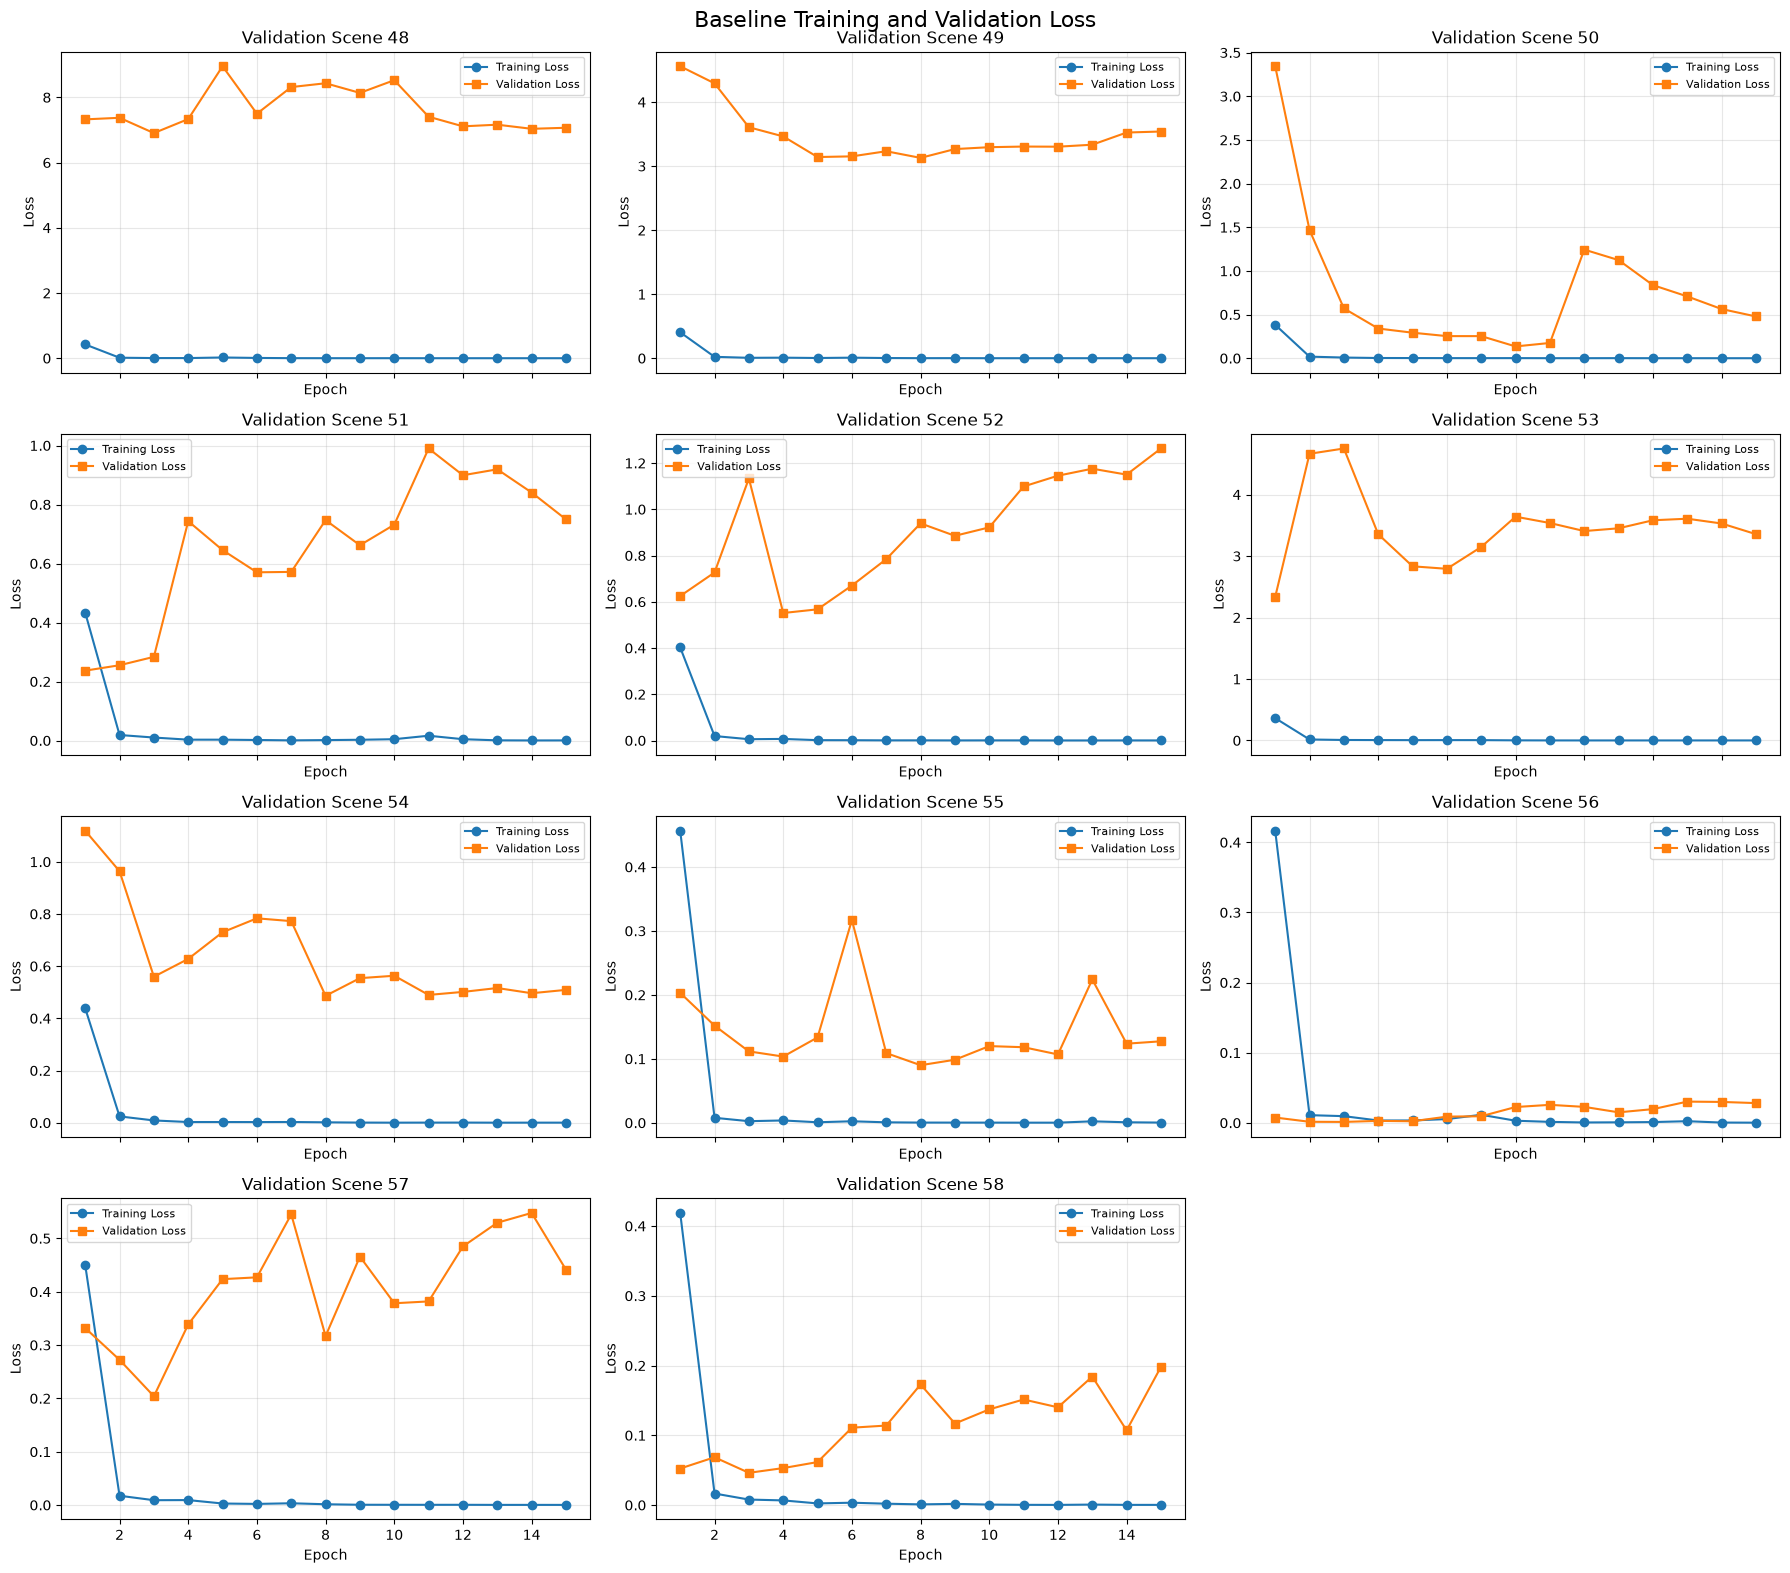

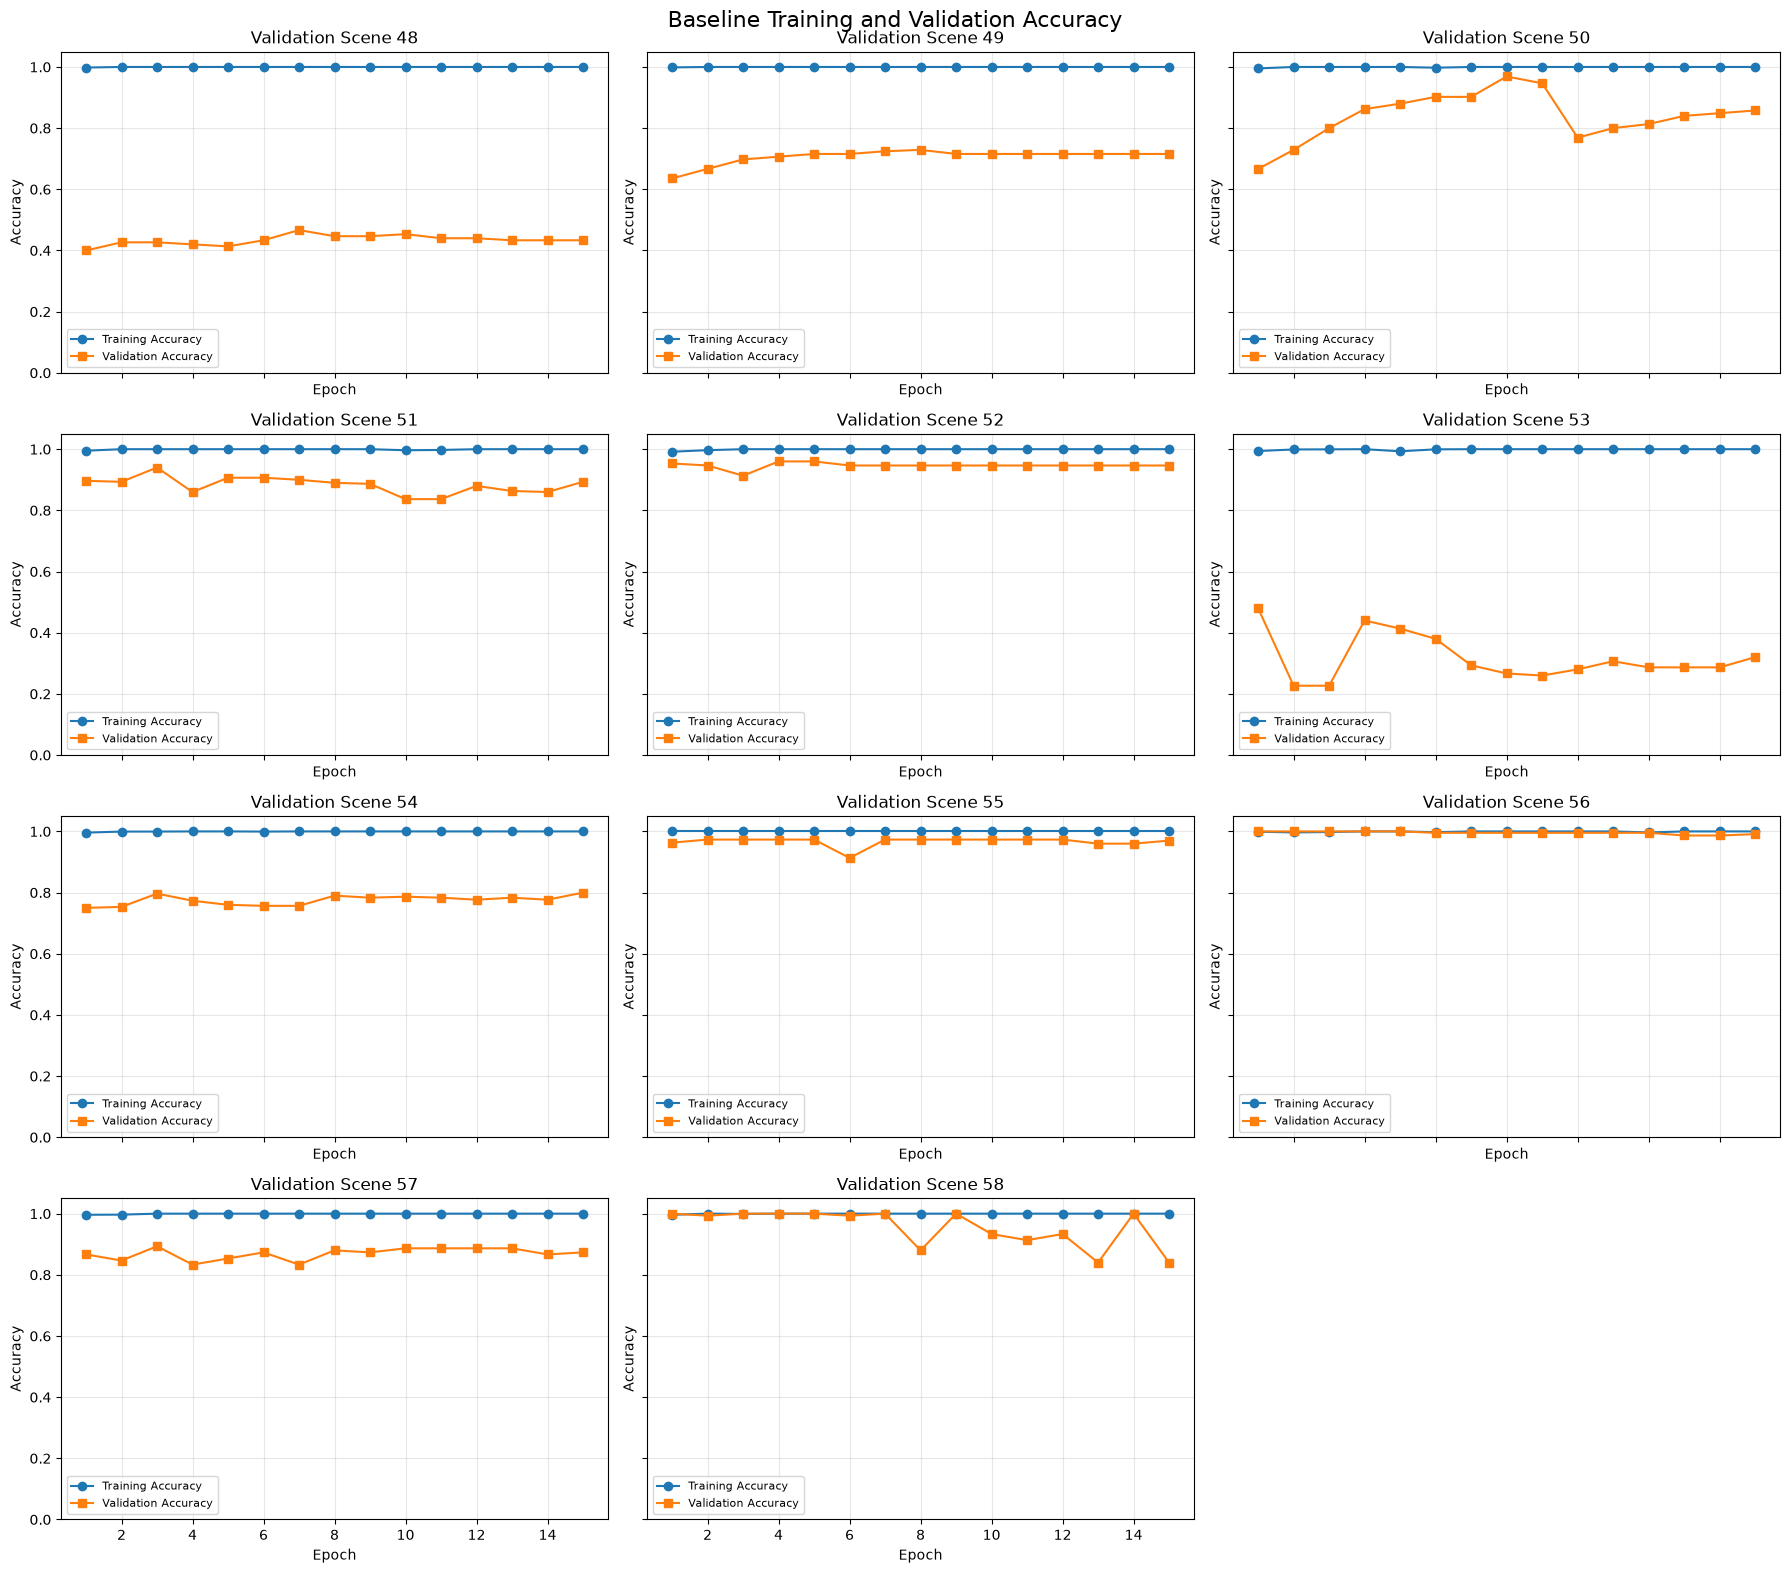

Baseline plots and results saved.
Loss curves: /Users/mac/Documents/MLInternship_week10/results/baseline_loss_curves.png
Accuracy curves: /Users/mac/Documents/MLInternship_week10/results/baseline_accuracy_curves.png
Fold results: /Users/mac/Documents/MLInternship_week10/results/baseline_loso_results.csv


In [11]:

# Cell 9 — Visualize Baseline Training Curves

num_folds = len(fold_histories)

# Create a grid for loss curves
fig, axes = plt.subplots(
    4, 3,
    figsize=(18, 16),
    sharex=True
)

axes = axes.flatten()

for fold_idx, history in enumerate(fold_histories):
    ax = axes[fold_idx]

    epochs_range = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epochs_range,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )

    ax.plot(
        epochs_range,
        history["val_loss"],
        marker="s",
        label="Validation Loss"
    )

    scene_id = fold_results[fold_idx]["scene_id"]

    ax.set_title(f"Validation Scene {scene_id}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

# Remove unused subplot
for ax in axes[num_folds:]:
    ax.remove()

fig.suptitle(
    "Baseline Training and Validation Loss",
    fontsize=16
)

fig.tight_layout()

loss_plot_path = RESULTS_DIR / "baseline_loss_curves.png"
fig.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
plt.show()


# Create a grid for accuracy curves
fig, axes = plt.subplots(
    4, 3,
    figsize=(18, 16),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for fold_idx, history in enumerate(fold_histories):
    ax = axes[fold_idx]

    epochs_range = range(1, len(history["train_accuracy"]) + 1)

    ax.plot(
        epochs_range,
        history["train_accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    ax.plot(
        epochs_range,
        history["val_accuracy"],
        marker="s",
        label="Validation Accuracy"
    )

    scene_id = fold_results[fold_idx]["scene_id"]

    ax.set_title(f"Validation Scene {scene_id}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

for ax in axes[num_folds:]:
    ax.remove()

fig.suptitle(
    "Baseline Training and Validation Accuracy",
    fontsize=16
)

fig.tight_layout()

accuracy_plot_path = RESULTS_DIR / "baseline_accuracy_curves.png"
fig.savefig(accuracy_plot_path, dpi=150, bbox_inches="tight")
plt.show()


# Save baseline experiment results
baseline_results_path = RESULTS_DIR / "baseline_loso_results.csv"

baseline_results_df.to_csv(
    baseline_results_path,
    index=False
)

np.save(
    RESULTS_DIR / "baseline_oof_predictions.npy",
    oof_predictions
)

print("Baseline plots and results saved.")
print("Loss curves:", loss_plot_path)
print("Accuracy curves:", accuracy_plot_path)
print("Fold results:", baseline_results_path)


In [12]:
# Cell 10 — Define Dropout Regularization Experiment

class YCBVDropoutMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)


dropout_model = YCBVDropoutMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

print("Dropout experiment model created.")
print(f"Input features: {INPUT_SIZE}")
print(f"Number of classes: {NUM_CLASSES}")
print("Dropout rates: 0.5 and 0.4")
print(f"Total parameters: {sum(p.numel() for p in dropout_model.parameters()):,}")

Dropout experiment model created.
Input features: 4096
Number of classes: 9
Dropout rates: 0.5 and 0.4
Total parameters: 1,082,889


In [15]:
# Cell 11 — Dropout Experiment: Leave-One-Scene-Out CV

dropout_oof_predictions = np.full(
    len(y_dev_encoded),
    -1,
    dtype=np.int64
)

dropout_fold_histories = []
dropout_fold_results = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    scene_id = int(groups_dev[val_idx][0])

    print(f"\n{'=' * 60}")
    print(f"Fold {fold}/11 | Validation Scene: {scene_id}")
    print(f"{'=' * 60}")

    # Split the current fold
    X_train_fold = X_dev_model[train_idx]
    X_val_fold = X_dev_model[val_idx]

    y_train_fold = y_dev_encoded[train_idx]
    y_val_fold = y_dev_encoded[val_idx]

    # Fit scaler only on training data
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)

    # Convert data to PyTorch tensors
    X_train_tensor = torch.tensor(
        X_train_scaled,
        dtype=torch.float32
    )

    X_val_tensor = torch.tensor(
        X_val_scaled,
        dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train_fold,
        dtype=torch.long
    )

    y_val_tensor = torch.tensor(
        y_val_fold,
        dtype=torch.long
    )

    # Create datasets
    train_dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    val_dataset = TensorDataset(
        X_val_tensor,
        y_val_tensor
    )

    # Set reproducible random seed
    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    # Reproducible training data shuffle
    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Initialize dropout model
    model = YCBVDropoutMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    # Optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Train model
    training_output = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        DEVICE
    )

    # Extract returned values from dictionary
    model = training_output["model"]
    history = training_output["history"]
    best_epoch = training_output["best_epoch"]
    best_val_loss = training_output["best_val_loss"]

    # Generate validation predictions
    model.eval()

    with torch.no_grad():
        logits = model(X_val_tensor.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

    # Store out-of-fold predictions
    dropout_oof_predictions[val_idx] = predictions

    # Calculate fold metrics
    fold_accuracy = accuracy_score(
        y_val_fold,
        predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    # Save fold history
    dropout_fold_histories.append(history)

    # Save fold results
    dropout_fold_results.append({
        "scene_id": scene_id,
        "samples": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_f1,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    })

    print(
        f"\nFold {fold} Summary | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro-F1: {fold_macro_f1:.4f} | "
        f"Best Epoch: {best_epoch}"
    )


# Calculate total training time
dropout_training_time = time.time() - start_time

# Create results DataFrame
dropout_results_df = pd.DataFrame(
    dropout_fold_results
)

# Verify that all development samples received predictions
assert np.all(dropout_oof_predictions >= 0), (
    "Some development samples have no predictions."
)

# Calculate overall OOF metrics
dropout_oof_accuracy = accuracy_score(
    y_dev_encoded,
    dropout_oof_predictions
)

dropout_oof_macro_f1 = f1_score(
    y_dev_encoded,
    dropout_oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("DROPOUT EXPERIMENT SUMMARY")
print("=" * 60)

print(f"OOF Accuracy: {dropout_oof_accuracy:.4f}")
print(f"OOF Macro-F1: {dropout_oof_macro_f1:.4f}")
print(f"Training Time: {dropout_training_time:.2f} seconds")

print("\nFold Results:")
display(dropout_results_df)


Fold 1/11 | Validation Scene: 48
Epoch [01/15] Train Loss: 0.5206 | Val Loss: 4.4484 | Train Acc: 0.9963 | Val Acc: 0.4133
Epoch [02/15] Train Loss: 0.0428 | Val Loss: 5.1613 | Train Acc: 0.9977 | Val Acc: 0.4467
Epoch [03/15] Train Loss: 0.0211 | Val Loss: 6.0811 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [04/15] Train Loss: 0.0106 | Val Loss: 5.7843 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [05/15] Train Loss: 0.0078 | Val Loss: 4.9578 | Train Acc: 1.0000 | Val Acc: 0.4667
Epoch [06/15] Train Loss: 0.0074 | Val Loss: 6.2461 | Train Acc: 1.0000 | Val Acc: 0.4600
Epoch [07/15] Train Loss: 0.0065 | Val Loss: 4.0945 | Train Acc: 1.0000 | Val Acc: 0.4800
Epoch [08/15] Train Loss: 0.0052 | Val Loss: 5.9009 | Train Acc: 0.9991 | Val Acc: 0.4667
Epoch [09/15] Train Loss: 0.0129 | Val Loss: 5.3219 | Train Acc: 1.0000 | Val Acc: 0.4733
Epoch [10/15] Train Loss: 0.0059 | Val Loss: 7.8951 | Train Acc: 1.0000 | Val Acc: 0.5267
Epoch [11/15] Train Loss: 0.0014 | Val Loss: 7.6130 | Train Acc: 1

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.480000,0.095172,0.428273,7,4.094478
1,49,225,0.657778,0.208184,0.624551,1,3.423302
2,50,225,1.000000,0.333333,1.000000,14,0.001548
3,51,300,0.913333,0.420411,0.945925,1,0.495838
4,52,150,0.973333,0.219178,0.986301,13,0.230504
5,53,150,0.233333,0.070707,0.318182,1,2.508565
6,54,300,0.840000,0.365515,0.822409,8,0.311176
7,55,300,0.973333,0.438260,0.986084,11,0.058976
8,56,225,1.000000,0.333333,1.000000,5,0.000393
9,57,150,0.920000,0.208411,0.937851,2,0.151102


In [14]:
# Inspect train_experiment return values

import inspect

print(inspect.getsource(train_experiment))

def train_experiment(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    epochs=EPOCHS
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    for epoch in range(epochs):

        # Training
        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        # Evaluate on training data
        train_metrics = evaluate_model(
            model,
            train_loader,
            criterion,
            device
        )

        # Validation
        val_metrics = evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )

        # Record metrics
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["l

In [16]:
# Cell 12 — Configure Weight Decay Experiment

WEIGHT_DECAY_EXPERIMENT = 1e-3

print("Weight Decay Experiment")
print(f"Baseline weight decay: {WEIGHT_DECAY}")
print(f"Experiment weight decay: {WEIGHT_DECAY_EXPERIMENT}")
print(f"Dropout rates: 0.3 and 0.2 (baseline)")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Epochs: {EPOCHS}")

Weight Decay Experiment
Baseline weight decay: 0.0001
Experiment weight decay: 0.001
Dropout rates: 0.3 and 0.2 (baseline)
Learning rate: 0.001
Epochs: 15


In [17]:
# Cell 13 — Weight Decay Experiment: Leave-One-Scene-Out CV

weight_decay_oof_predictions = np.full(
    len(y_dev_encoded), -1, dtype=np.int64
)

weight_decay_fold_histories = []
weight_decay_fold_results = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    scene_id = int(groups_dev[val_idx][0])

    print(f"\n{'=' * 60}")
    print(f"Fold {fold}/11 | Validation Scene: {scene_id}")
    print(f"{'=' * 60}")

    X_train_fold = X_dev_model[train_idx]
    X_val_fold = X_dev_model[val_idx]

    y_train_fold = y_dev_encoded[train_idx]
    y_val_fold = y_dev_encoded[val_idx]

    # Fit scaler only on training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)

    # Convert to tensors
    X_train_tensor = torch.tensor(
        X_train_scaled, dtype=torch.float32
    )
    X_val_tensor = torch.tensor(
        X_val_scaled, dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train_fold, dtype=torch.long
    )
    y_val_tensor = torch.tensor(
        y_val_fold, dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_train_tensor, y_train_tensor
    )
    val_dataset = TensorDataset(
        X_val_tensor, y_val_tensor
    )

    # Reproducible random seed
    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Baseline architecture and dropout rates
    model = YCBVBaselineMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY_EXPERIMENT
    )

    # Train model
    training_output = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        DEVICE
    )

    model = training_output["model"]
    history = training_output["history"]
    best_epoch = training_output["best_epoch"]
    best_val_loss = training_output["best_val_loss"]

    # Generate predictions
    model.eval()

    with torch.no_grad():
        logits = model(X_val_tensor.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

    weight_decay_oof_predictions[val_idx] = predictions

    # Calculate metrics
    fold_accuracy = accuracy_score(
        y_val_fold, predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    weight_decay_fold_histories.append(history)

    weight_decay_fold_results.append({
        "scene_id": scene_id,
        "samples": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_f1,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    })

    print(
        f"\nFold {fold} Summary | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro-F1: {fold_macro_f1:.4f} | "
        f"Best Epoch: {best_epoch}"
    )


# Training time
weight_decay_training_time = time.time() - start_time

# Create results DataFrame
weight_decay_results_df = pd.DataFrame(
    weight_decay_fold_results
)

# Verify predictions
assert np.all(weight_decay_oof_predictions >= 0), (
    "Some development samples have no predictions."
)

# Overall OOF metrics
weight_decay_oof_accuracy = accuracy_score(
    y_dev_encoded,
    weight_decay_oof_predictions
)

weight_decay_oof_macro_f1 = f1_score(
    y_dev_encoded,
    weight_decay_oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("WEIGHT DECAY EXPERIMENT SUMMARY")
print("=" * 60)

print(f"OOF Accuracy: {weight_decay_oof_accuracy:.4f}")
print(f"OOF Macro-F1: {weight_decay_oof_macro_f1:.4f}")
print(f"Training Time: {weight_decay_training_time:.2f} seconds")

print("\nFold Results:")
display(weight_decay_results_df)


Fold 1/11 | Validation Scene: 48
Epoch [01/15] Train Loss: 0.3922 | Val Loss: 4.5012 | Train Acc: 0.9954 | Val Acc: 0.4200
Epoch [02/15] Train Loss: 0.0219 | Val Loss: 5.1586 | Train Acc: 1.0000 | Val Acc: 0.4200
Epoch [03/15] Train Loss: 0.0140 | Val Loss: 5.0762 | Train Acc: 1.0000 | Val Acc: 0.4467
Epoch [04/15] Train Loss: 0.0033 | Val Loss: 4.8762 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [05/15] Train Loss: 0.0018 | Val Loss: 4.2839 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [06/15] Train Loss: 0.0039 | Val Loss: 5.6320 | Train Acc: 1.0000 | Val Acc: 0.4867
Epoch [07/15] Train Loss: 0.0042 | Val Loss: 5.3541 | Train Acc: 1.0000 | Val Acc: 0.4733
Epoch [08/15] Train Loss: 0.0020 | Val Loss: 4.6243 | Train Acc: 1.0000 | Val Acc: 0.4800
Epoch [09/15] Train Loss: 0.0052 | Val Loss: 5.1161 | Train Acc: 1.0000 | Val Acc: 0.4800
Epoch [10/15] Train Loss: 0.0036 | Val Loss: 4.8420 | Train Acc: 1.0000 | Val Acc: 0.4667
Epoch [11/15] Train Loss: 0.0032 | Val Loss: 4.7417 | Train Acc: 1

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.466667,0.082091,0.369408,13,4.259890
1,49,225,0.697778,0.224397,0.673190,14,2.289476
2,50,225,0.982222,0.328133,0.984400,12,0.025627
3,51,300,0.873333,0.399384,0.898614,15,0.380155
4,52,150,0.966667,0.218391,0.982759,3,0.295243
5,53,150,0.246667,0.073413,0.330357,1,2.388445
6,54,300,0.850000,0.369227,0.830760,6,0.353594
7,55,300,0.976667,0.434732,0.978147,3,0.078176
8,56,225,1.000000,0.333333,1.000000,4,0.000528
9,57,150,0.920000,0.212862,0.957881,2,0.216046


In [19]:
# Cell 14 — Controlled Baseline Re-run

controlled_baseline_oof_predictions = np.full(
    len(y_dev_encoded), -1, dtype=np.int64
)

controlled_baseline_fold_histories = []
controlled_baseline_fold_results = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    scene_id = int(groups_dev[val_idx][0])

    print(f"\n{'=' * 60}")
    print(f"Fold {fold}/11 | Validation Scene: {scene_id}")
    print(f"{'=' * 60}")

    X_train_fold = X_dev_model[train_idx]
    X_val_fold = X_dev_model[val_idx]

    y_train_fold = y_dev_encoded[train_idx]
    y_val_fold = y_dev_encoded[val_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)

    X_train_tensor = torch.tensor(
        X_train_scaled, dtype=torch.float32
    )
    X_val_tensor = torch.tensor(
        X_val_scaled, dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train_fold, dtype=torch.long
    )
    y_val_tensor = torch.tensor(
        y_val_fold, dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_train_tensor, y_train_tensor
    )
    val_dataset = TensorDataset(
        X_val_tensor, y_val_tensor
    )

    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model = YCBVBaselineMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    training_output = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        DEVICE
    )

    model = training_output["model"]
    history = training_output["history"]

    predictions = []

    model.eval()
    with torch.no_grad():
        logits = model(X_val_tensor.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

    controlled_baseline_oof_predictions[val_idx] = predictions

    fold_accuracy = accuracy_score(
        y_val_fold, predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    controlled_baseline_fold_histories.append(history)

    controlled_baseline_fold_results.append({
        "scene_id": scene_id,
        "samples": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_f1,
        "best_epoch": training_output["best_epoch"],
        "best_val_loss": training_output["best_val_loss"]
    })

    print(
        f"\nFold {fold} Summary | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro-F1: {fold_macro_f1:.4f} | "
        f"Best Epoch: {training_output['best_epoch']}"
    )


controlled_baseline_training_time = time.time() - start_time

controlled_baseline_results_df = pd.DataFrame(
    controlled_baseline_fold_results
)

assert np.all(controlled_baseline_oof_predictions >= 0)

controlled_baseline_oof_accuracy = accuracy_score(
    y_dev_encoded,
    controlled_baseline_oof_predictions
)

controlled_baseline_oof_macro_f1 = f1_score(
    y_dev_encoded,
    controlled_baseline_oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("CONTROLLED BASELINE SUMMARY")
print("=" * 60)

print(f"OOF Accuracy: {controlled_baseline_oof_accuracy:.4f}")
print(f"OOF Macro-F1: {controlled_baseline_oof_macro_f1:.4f}")
print(f"Training Time: {controlled_baseline_training_time:.2f} seconds")

display(controlled_baseline_results_df)


Fold 1/11 | Validation Scene: 48
Epoch [01/15] Train Loss: 0.3917 | Val Loss: 4.7217 | Train Acc: 0.9931 | Val Acc: 0.4200
Epoch [02/15] Train Loss: 0.0228 | Val Loss: 5.7152 | Train Acc: 1.0000 | Val Acc: 0.4267
Epoch [03/15] Train Loss: 0.0134 | Val Loss: 6.0143 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [04/15] Train Loss: 0.0025 | Val Loss: 6.3128 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [05/15] Train Loss: 0.0010 | Val Loss: 6.2980 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [06/15] Train Loss: 0.0016 | Val Loss: 5.7306 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [07/15] Train Loss: 0.0011 | Val Loss: 5.9005 | Train Acc: 1.0000 | Val Acc: 0.4600
Epoch [08/15] Train Loss: 0.0006 | Val Loss: 5.7465 | Train Acc: 1.0000 | Val Acc: 0.4600
Epoch [09/15] Train Loss: 0.0012 | Val Loss: 5.6704 | Train Acc: 0.9982 | Val Acc: 0.4600
Epoch [10/15] Train Loss: 0.0018 | Val Loss: 7.5746 | Train Acc: 1.0000 | Val Acc: 0.4333
Epoch [11/15] Train Loss: 0.0007 | Val Loss: 8.1807 | Train Acc: 1

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.420000,0.097292,0.437815,1,4.721731
1,49,225,0.715556,0.224520,0.673559,8,3.247810
2,50,225,0.951111,0.316949,0.950847,7,0.168686
3,51,300,0.863333,0.406136,0.913807,1,0.505562
4,52,150,0.966667,0.218391,0.982759,3,0.271671
5,53,150,0.246667,0.073413,0.330357,1,2.394256
6,54,300,0.873333,0.382880,0.861480,8,0.286144
7,55,300,0.976667,0.434051,0.976616,3,0.085143
8,56,225,1.000000,0.333333,1.000000,4,0.000163
9,57,150,0.893333,0.209691,0.943610,2,0.239918


In [20]:
# Cell 15 — Define Kaiming Initialization

def initialize_kaiming(model):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(
                module.weight,
                mode="fan_in",
                nonlinearity="relu"
            )
            nn.init.zeros_(module.bias)

    return model


# Create a model and inspect initialization
kaiming_model = YCBVBaselineMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

kaiming_model = initialize_kaiming(kaiming_model)

print("Kaiming initialization applied successfully.")
print(f"Input size: {INPUT_SIZE}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Total parameters: {sum(p.numel() for p in kaiming_model.parameters()):,}")

print("\nFirst layer weight statistics:")
print(f"Mean: {kaiming_model.network[0].weight.mean().item():.6f}")
print(f"Std:  {kaiming_model.network[0].weight.std().item():.6f}")

Kaiming initialization applied successfully.
Input size: 4096
Number of classes: 9
Total parameters: 1,082,889

First layer weight statistics:
Mean: -0.000016
Std:  0.022116


In [21]:
# Cell 16 — Kaiming Initialization: Leave-One-Scene-Out CV

kaiming_oof_predictions = np.full(
    len(y_dev_encoded), -1, dtype=np.int64
)

kaiming_fold_histories = []
kaiming_fold_results = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    scene_id = int(groups_dev[val_idx][0])

    print(f"\n{'=' * 60}")
    print(f"Fold {fold}/11 | Validation Scene: {scene_id}")
    print(f"{'=' * 60}")

    X_train_fold = X_dev_model[train_idx]
    X_val_fold = X_dev_model[val_idx]

    y_train_fold = y_dev_encoded[train_idx]
    y_val_fold = y_dev_encoded[val_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)

    X_train_tensor = torch.tensor(
        X_train_scaled, dtype=torch.float32
    )
    X_val_tensor = torch.tensor(
        X_val_scaled, dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train_fold, dtype=torch.long
    )
    y_val_tensor = torch.tensor(
        y_val_fold, dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_train_tensor, y_train_tensor
    )
    val_dataset = TensorDataset(
        X_val_tensor, y_val_tensor
    )

    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Same architecture, different initialization
    model = YCBVBaselineMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    model = initialize_kaiming(model)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    training_output = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        DEVICE
    )

    model = training_output["model"]
    history = training_output["history"]

    model.eval()
    with torch.no_grad():
        logits = model(X_val_tensor.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

    kaiming_oof_predictions[val_idx] = predictions

    fold_accuracy = accuracy_score(
        y_val_fold, predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    kaiming_fold_histories.append(history)

    kaiming_fold_results.append({
        "scene_id": scene_id,
        "samples": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_f1,
        "best_epoch": training_output["best_epoch"],
        "best_val_loss": training_output["best_val_loss"]
    })

    print(
        f"\nFold {fold} Summary | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro-F1: {fold_macro_f1:.4f} | "
        f"Best Epoch: {training_output['best_epoch']}"
    )


kaiming_training_time = time.time() - start_time

kaiming_results_df = pd.DataFrame(
    kaiming_fold_results
)

assert np.all(kaiming_oof_predictions >= 0)

kaiming_oof_accuracy = accuracy_score(
    y_dev_encoded,
    kaiming_oof_predictions
)

kaiming_oof_macro_f1 = f1_score(
    y_dev_encoded,
    kaiming_oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("KAIMING INITIALIZATION SUMMARY")
print("=" * 60)

print(f"OOF Accuracy: {kaiming_oof_accuracy:.4f}")
print(f"OOF Macro-F1: {kaiming_oof_macro_f1:.4f}")
print(f"Training Time: {kaiming_training_time:.2f} seconds")

display(kaiming_results_df)


Fold 1/11 | Validation Scene: 48
Epoch [01/15] Train Loss: 0.3594 | Val Loss: 7.2551 | Train Acc: 0.9963 | Val Acc: 0.4200
Epoch [02/15] Train Loss: 0.0325 | Val Loss: 3.7025 | Train Acc: 0.9968 | Val Acc: 0.4667
Epoch [03/15] Train Loss: 0.0206 | Val Loss: 3.4819 | Train Acc: 0.9968 | Val Acc: 0.4533
Epoch [04/15] Train Loss: 0.0044 | Val Loss: 4.4343 | Train Acc: 1.0000 | Val Acc: 0.4200
Epoch [05/15] Train Loss: 0.0051 | Val Loss: 4.9458 | Train Acc: 1.0000 | Val Acc: 0.4200
Epoch [06/15] Train Loss: 0.0046 | Val Loss: 3.1349 | Train Acc: 1.0000 | Val Acc: 0.5067
Epoch [07/15] Train Loss: 0.0050 | Val Loss: 14.5367 | Train Acc: 1.0000 | Val Acc: 0.2267
Epoch [08/15] Train Loss: 0.0083 | Val Loss: 10.7101 | Train Acc: 0.9968 | Val Acc: 0.4267
Epoch [09/15] Train Loss: 0.0050 | Val Loss: 8.0682 | Train Acc: 1.0000 | Val Acc: 0.4600
Epoch [10/15] Train Loss: 0.0031 | Val Loss: 12.0184 | Train Acc: 1.0000 | Val Acc: 0.2133
Epoch [11/15] Train Loss: 0.0005 | Val Loss: 14.1509 | Train Ac

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.506667,0.148323,0.667453,6,3.134912
1,49,225,0.684444,0.230598,0.691794,3,5.331203
2,50,225,1.000000,0.333333,1.000000,12,0.000357
3,51,300,0.863333,0.398973,0.897689,1,0.443112
4,52,150,0.966667,0.218391,0.982759,7,0.327231
5,53,150,0.286667,0.080979,0.364407,5,3.891862
6,54,300,0.800000,0.345531,0.777445,6,0.436485
7,55,300,0.963333,0.435917,0.980813,7,0.117331
8,56,225,1.000000,0.333333,1.000000,15,0.000092
9,57,150,0.880000,0.205992,0.926965,1,0.351934


In [22]:
# Cell 17 — Define Xavier Initialization

def initialize_xavier(model):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    return model


# Create and initialize a model
xavier_model = YCBVBaselineMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

xavier_model = initialize_xavier(xavier_model)

print("Xavier initialization applied successfully.")
print(f"Input size: {INPUT_SIZE}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Total parameters: {sum(p.numel() for p in xavier_model.parameters()):,}")

print("\nFirst layer weight statistics:")
print(f"Mean: {xavier_model.network[0].weight.mean().item():.6f}")
print(f"Std:  {xavier_model.network[0].weight.std().item():.6f}")

Xavier initialization applied successfully.
Input size: 4096
Number of classes: 9
Total parameters: 1,082,889

First layer weight statistics:
Mean: -0.000016
Std:  0.021433


In [23]:
# Cell 18 — Xavier Initialization: Leave-One-Scene-Out CV

xavier_oof_predictions = np.full(
    len(y_dev_encoded), -1, dtype=np.int64
)

xavier_fold_histories = []
xavier_fold_results = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    scene_id = int(groups_dev[val_idx][0])

    print(f"\n{'=' * 60}")
    print(f"Fold {fold}/11 | Validation Scene: {scene_id}")
    print(f"{'=' * 60}")

    X_train_fold = X_dev_model[train_idx]
    X_val_fold = X_dev_model[val_idx]

    y_train_fold = y_dev_encoded[train_idx]
    y_val_fold = y_dev_encoded[val_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)

    X_train_tensor = torch.tensor(
        X_train_scaled, dtype=torch.float32
    )
    X_val_tensor = torch.tensor(
        X_val_scaled, dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train_fold, dtype=torch.long
    )
    y_val_tensor = torch.tensor(
        y_val_fold, dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_train_tensor, y_train_tensor
    )
    val_dataset = TensorDataset(
        X_val_tensor, y_val_tensor
    )

    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Same architecture and training settings
    model = YCBVBaselineMLP(
        input_size=INPUT_SIZE,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    model = initialize_xavier(model)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    training_output = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        DEVICE
    )

    model = training_output["model"]
    history = training_output["history"]

    model.eval()
    with torch.no_grad():
        logits = model(X_val_tensor.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

    xavier_oof_predictions[val_idx] = predictions

    fold_accuracy = accuracy_score(
        y_val_fold, predictions
    )

    fold_macro_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    present_labels = np.unique(y_val_fold)

    fold_present_f1 = f1_score(
        y_val_fold,
        predictions,
        labels=present_labels,
        average="macro",
        zero_division=0
    )

    xavier_fold_histories.append(history)

    xavier_fold_results.append({
        "scene_id": scene_id,
        "samples": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1_all_classes": fold_macro_f1,
        "macro_f1_present_classes": fold_present_f1,
        "best_epoch": training_output["best_epoch"],
        "best_val_loss": training_output["best_val_loss"]
    })

    print(
        f"\nFold {fold} Summary | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro-F1: {fold_macro_f1:.4f} | "
        f"Best Epoch: {training_output['best_epoch']}"
    )


xavier_training_time = time.time() - start_time

xavier_results_df = pd.DataFrame(
    xavier_fold_results
)

assert np.all(xavier_oof_predictions >= 0)

xavier_oof_accuracy = accuracy_score(
    y_dev_encoded,
    xavier_oof_predictions
)

xavier_oof_macro_f1 = f1_score(
    y_dev_encoded,
    xavier_oof_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("XAVIER INITIALIZATION SUMMARY")
print("=" * 60)

print(f"OOF Accuracy: {xavier_oof_accuracy:.4f}")
print(f"OOF Macro-F1: {xavier_oof_macro_f1:.4f}")
print(f"Training Time: {xavier_training_time:.2f} seconds")

display(xavier_results_df)


Fold 1/11 | Validation Scene: 48
Epoch [01/15] Train Loss: 0.3122 | Val Loss: 9.7037 | Train Acc: 0.9968 | Val Acc: 0.2200
Epoch [02/15] Train Loss: 0.0277 | Val Loss: 10.4733 | Train Acc: 1.0000 | Val Acc: 0.2200
Epoch [03/15] Train Loss: 0.0091 | Val Loss: 10.4884 | Train Acc: 1.0000 | Val Acc: 0.1467
Epoch [04/15] Train Loss: 0.0066 | Val Loss: 12.5614 | Train Acc: 1.0000 | Val Acc: 0.1800
Epoch [05/15] Train Loss: 0.0037 | Val Loss: 12.6173 | Train Acc: 1.0000 | Val Acc: 0.1800
Epoch [06/15] Train Loss: 0.0016 | Val Loss: 11.9654 | Train Acc: 1.0000 | Val Acc: 0.1933
Epoch [07/15] Train Loss: 0.0058 | Val Loss: 9.6491 | Train Acc: 1.0000 | Val Acc: 0.2000
Epoch [08/15] Train Loss: 0.0049 | Val Loss: 11.4381 | Train Acc: 0.9968 | Val Acc: 0.2000
Epoch [09/15] Train Loss: 0.0098 | Val Loss: 11.0287 | Train Acc: 1.0000 | Val Acc: 0.2000
Epoch [10/15] Train Loss: 0.0017 | Val Loss: 10.8258 | Train Acc: 0.9995 | Val Acc: 0.1933
Epoch [11/15] Train Loss: 0.0023 | Val Loss: 10.6916 | Tra

,scene_id,samples,accuracy,macro_f1_all_classes,macro_f1_present_classes,best_epoch,best_val_loss
0,48,150,0.206667,0.067806,0.305128,15,9.570109
1,49,225,0.711111,0.240208,0.720624,4,3.047305
2,50,225,0.977778,0.325918,0.977753,6,0.084985
3,51,300,0.806667,0.371651,0.836214,2,0.856593
4,52,150,1.000000,0.222222,1.000000,6,0.000071
5,53,150,0.253333,0.074730,0.336283,1,4.128994
6,54,300,0.856667,0.379495,0.853865,1,0.384879
7,55,300,0.973333,0.434676,0.978022,8,0.093959
8,56,225,1.000000,0.333333,1.000000,11,0.000108
9,57,150,0.880000,0.207071,0.931818,1,0.502736


In [24]:
# Cell 19 — Compare All Experiments

experiment_comparison = pd.DataFrame([
    {
        "experiment": "Controlled Baseline",
        "initialization": "PyTorch Default",
        "dropout": "0.3 / 0.2",
        "weight_decay": 1e-4,
        "oof_accuracy": 0.8357,
        "oof_macro_f1": 0.7749
    },
    {
        "experiment": "Increased Dropout",
        "initialization": "PyTorch Default",
        "dropout": "0.5 / 0.4",
        "weight_decay": 1e-4,
        "oof_accuracy": dropout_oof_accuracy,
        "oof_macro_f1": dropout_oof_macro_f1
    },
    {
        "experiment": "Increased Weight Decay",
        "initialization": "PyTorch Default",
        "dropout": "0.3 / 0.2",
        "weight_decay": WEIGHT_DECAY_EXPERIMENT,
        "oof_accuracy": weight_decay_oof_accuracy,
        "oof_macro_f1": weight_decay_oof_macro_f1
    },
    {
        "experiment": "Kaiming Normal",
        "initialization": "Kaiming Normal",
        "dropout": "0.3 / 0.2",
        "weight_decay": 1e-4,
        "oof_accuracy": kaiming_oof_accuracy,
        "oof_macro_f1": kaiming_oof_macro_f1
    },
    {
        "experiment": "Xavier Uniform",
        "initialization": "Xavier Uniform",
        "dropout": "0.3 / 0.2",
        "weight_decay": 1e-4,
        "oof_accuracy": xavier_oof_accuracy,
        "oof_macro_f1": xavier_oof_macro_f1
    }
])

experiment_comparison["accuracy_percent"] = (
    experiment_comparison["oof_accuracy"] * 100
)

experiment_comparison["macro_f1_percent"] = (
    experiment_comparison["oof_macro_f1"] * 100
)

experiment_comparison = experiment_comparison.sort_values(
    "oof_macro_f1",
    ascending=False
).reset_index(drop=True)

display(experiment_comparison.round(4))

experiment_comparison.to_csv(
    RESULTS_DIR / "experiment_comparison.csv",
    index=False
)

print("\nComparison table saved successfully.")

,experiment,initialization,dropout,weight_decay,oof_accuracy,oof_macro_f1,accuracy_percent,macro_f1_percent
0,Increased Weight Decay,PyTorch Default,0.3 / 0.2,0.0010,0.8400,0.7821,84.0000,78.2108
1,Controlled Baseline,PyTorch Default,0.3 / 0.2,0.0001,0.8357,0.7749,83.5700,77.4900
2,Kaiming Normal,Kaiming Normal,0.3 / 0.2,0.0001,0.8335,0.7677,83.3548,76.7731
3,Increased Dropout,PyTorch Default,0.5 / 0.4,0.0001,0.8417,0.7645,84.1720,76.4468
4,Xavier Uniform,Xavier Uniform,0.3 / 0.2,0.0001,0.8159,0.7597,81.5914,75.9746



Comparison table saved successfully.


In [25]:
# Cell 20 — Per-Scene Performance Comparison

scene_comparison = pd.DataFrame({
    "scene_id": controlled_baseline_results_df["scene_id"],
    "baseline_accuracy": controlled_baseline_results_df["accuracy"],
    "weight_decay_accuracy": weight_decay_results_df["accuracy"],
    "baseline_macro_f1": controlled_baseline_results_df[
        "macro_f1_all_classes"
    ],
    "weight_decay_macro_f1": weight_decay_results_df[
        "macro_f1_all_classes"
    ]
})

scene_comparison["accuracy_change"] = (
    scene_comparison["weight_decay_accuracy"]
    - scene_comparison["baseline_accuracy"]
)

scene_comparison["macro_f1_change"] = (
    scene_comparison["weight_decay_macro_f1"]
    - scene_comparison["baseline_macro_f1"]
)

scene_comparison = scene_comparison.sort_values(
    "scene_id"
).reset_index(drop=True)

display(scene_comparison.round(4))

scene_comparison.to_csv(
    RESULTS_DIR / "per_scene_weight_decay_comparison.csv",
    index=False
)

print("\nPer-scene comparison saved successfully.")

,scene_id,baseline_accuracy,weight_decay_accuracy,baseline_macro_f1,weight_decay_macro_f1,accuracy_change,macro_f1_change
0,48,0.4200,0.4667,0.0973,0.0821,0.0467,-0.0152
1,49,0.7156,0.6978,0.2245,0.2244,-0.0178,-0.0001
2,50,0.9511,0.9822,0.3169,0.3281,0.0311,0.0112
3,51,0.8633,0.8733,0.4061,0.3994,0.0100,-0.0068
4,52,0.9667,0.9667,0.2184,0.2184,0.0000,0.0000
5,53,0.2467,0.2467,0.0734,0.0734,0.0000,0.0000
6,54,0.8733,0.8500,0.3829,0.3692,-0.0233,-0.0137
7,55,0.9767,0.9767,0.4341,0.4347,0.0000,0.0007
8,56,1.0000,1.0000,0.3333,0.3333,0.0000,0.0000
9,57,0.8933,0.9200,0.2097,0.2129,0.0267,0.0032



Per-scene comparison saved successfully.


In [26]:
# Cell 21 — Inspect Available Training Histories

history_variables = [
    name for name, value in globals().items()
    if "histor" in name.lower()
    and isinstance(value, (list, dict))
]

print("Available training history variables:\n")

for name in history_variables:
    value = globals()[name]
    print(
        f"{name}: "
        f"type={type(value).__name__}, "
        f"length={len(value)}"
    )

Available training history variables:

fold_histories: type=list, length=11
history: type=dict, length=4
dropout_fold_histories: type=list, length=11
weight_decay_fold_histories: type=list, length=2
controlled_baseline_fold_histories: type=list, length=11
kaiming_fold_histories: type=list, length=11
xavier_fold_histories: type=list, length=11


In [27]:
# Cell 22 — Inspect History Structures

history_collections = {
    "Controlled Baseline": controlled_baseline_fold_histories,
    "Increased Dropout": dropout_fold_histories,
    "Increased Weight Decay": weight_decay_fold_histories,
    "Kaiming Normal": kaiming_fold_histories,
    "Xavier Uniform": xavier_fold_histories,
}

for experiment_name, histories in history_collections.items():
    print(f"\n{experiment_name}")
    print("-" * 50)
    print(f"Number of folds: {len(histories)}")

    if len(histories) > 0:
        first_history = histories[0]
        print(f"First item type: {type(first_history).__name__}")

        if isinstance(first_history, dict):
            print(f"Keys: {list(first_history.keys())}")

            for key, value in first_history.items():
                if isinstance(value, (list, tuple, np.ndarray)):
                    print(f"  {key}: length={len(value)}")
                else:
                    print(f"  {key}: {type(value).__name__}")


Controlled Baseline
--------------------------------------------------
Number of folds: 11
First item type: dict
Keys: ['train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']
  train_loss: length=15
  val_loss: length=15
  train_accuracy: length=15
  val_accuracy: length=15

Increased Dropout
--------------------------------------------------
Number of folds: 11
First item type: dict
Keys: ['train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']
  train_loss: length=15
  val_loss: length=15
  train_accuracy: length=15
  val_accuracy: length=15

Increased Weight Decay
--------------------------------------------------
Number of folds: 2
First item type: dict
Keys: ['train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']
  train_loss: length=15
  val_loss: length=15
  train_accuracy: length=15
  val_accuracy: length=15

Kaiming Normal
--------------------------------------------------
Number of folds: 11
First item type: dict
Keys: ['train_loss', 'val_loss', 'train_accuracy

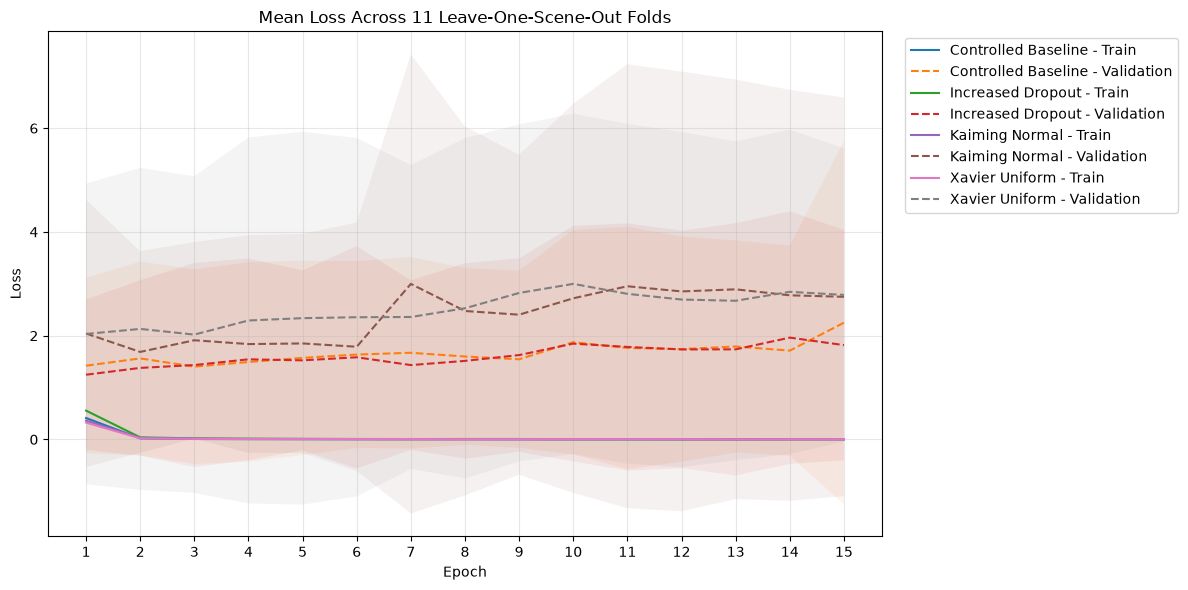

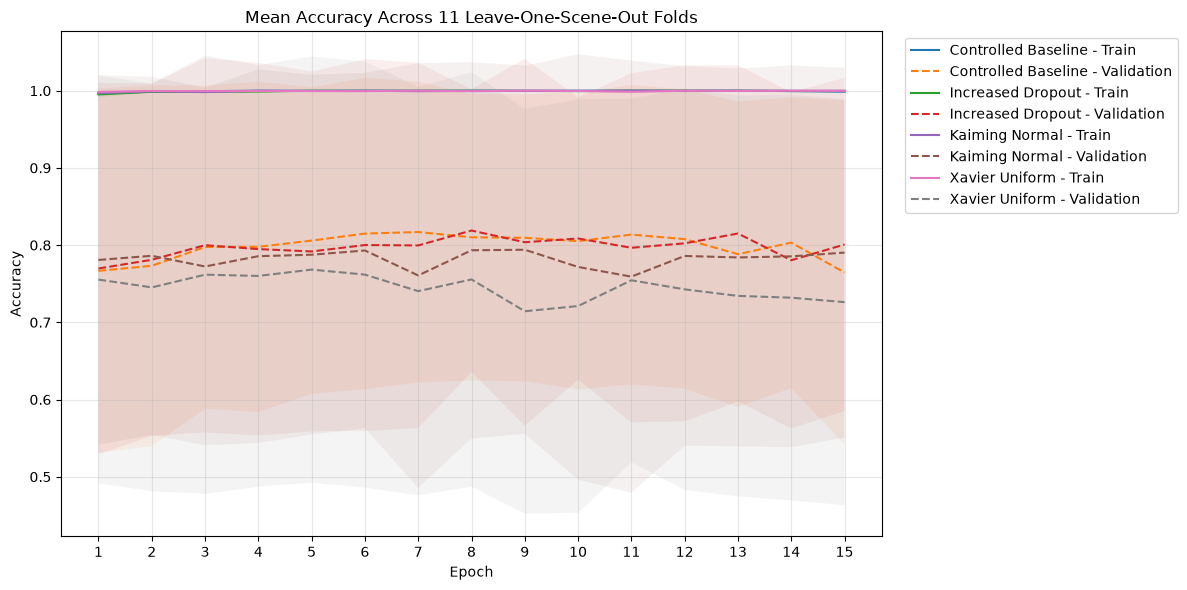

Training and validation curves saved successfully.


In [28]:
# Cell 23 — Plot Mean Training and Validation Curves

import matplotlib.pyplot as plt

plot_histories = {
    "Controlled Baseline": controlled_baseline_fold_histories,
    "Increased Dropout": dropout_fold_histories,
    "Kaiming Normal": kaiming_fold_histories,
    "Xavier Uniform": xavier_fold_histories,
}

metrics = [
    ("train_loss", "val_loss", "Loss"),
    ("train_accuracy", "val_accuracy", "Accuracy")
]

for train_metric, val_metric, metric_name in metrics:

    plt.figure(figsize=(12, 6))

    for experiment_name, histories in plot_histories.items():

        train_values = np.array([
            fold[train_metric] for fold in histories
        ])

        val_values = np.array([
            fold[val_metric] for fold in histories
        ])

        epochs_range = np.arange(1, train_values.shape[1] + 1)

        train_mean = train_values.mean(axis=0)
        train_std = train_values.std(axis=0)

        val_mean = val_values.mean(axis=0)
        val_std = val_values.std(axis=0)

        plt.plot(
            epochs_range,
            train_mean,
            label=f"{experiment_name} - Train"
        )

        plt.fill_between(
            epochs_range,
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.08
        )

        plt.plot(
            epochs_range,
            val_mean,
            linestyle="--",
            label=f"{experiment_name} - Validation"
        )

        plt.fill_between(
            epochs_range,
            val_mean - val_std,
            val_mean + val_std,
            alpha=0.08
        )

    plt.xlabel("Epoch")
    plt.ylabel(metric_name)
    plt.title(f"Mean {metric_name} Across 11 Leave-One-Scene-Out Folds")
    plt.xticks(epochs_range)
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()

    filename = f"training_curves_{metric_name.lower()}.png"

    plt.savefig(
        RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Training and validation curves saved successfully.")

In [29]:
# Cell 24 — Quantify the Overfitting Gap

selected_epochs = [1, 2, 5, 10, 15]

overfitting_summary = []

for experiment_name, histories in plot_histories.items():

    for epoch in selected_epochs:
        epoch_index = epoch - 1

        train_loss = np.array([
            fold["train_loss"][epoch_index]
            for fold in histories
        ])

        val_loss = np.array([
            fold["val_loss"][epoch_index]
            for fold in histories
        ])

        train_accuracy = np.array([
            fold["train_accuracy"][epoch_index]
            for fold in histories
        ])

        val_accuracy = np.array([
            fold["val_accuracy"][epoch_index]
            for fold in histories
        ])

        overfitting_summary.append({
            "experiment": experiment_name,
            "epoch": epoch,
            "train_loss_mean": train_loss.mean(),
            "val_loss_mean": val_loss.mean(),
            "loss_gap": (val_loss - train_loss).mean(),
            "train_accuracy_mean": train_accuracy.mean(),
            "val_accuracy_mean": val_accuracy.mean(),
            "accuracy_gap": (
                train_accuracy - val_accuracy
            ).mean()
        })

overfitting_summary_df = pd.DataFrame(overfitting_summary)

display(overfitting_summary_df.round(4))

overfitting_summary_df.to_csv(
    RESULTS_DIR / "overfitting_gap_analysis.csv",
    index=False
)

print("\nOverfitting analysis saved successfully.")

,experiment,epoch,train_loss_mean,val_loss_mean,loss_gap,train_accuracy_mean,val_accuracy_mean,accuracy_gap
0,Controlled Baseline,1,0.4122,1.4214,1.0092,0.9961,0.7667,0.2294
1,Controlled Baseline,2,0.0191,1.5614,1.5422,0.9989,0.7732,0.2256
2,Controlled Baseline,5,0.0035,1.5722,1.5687,0.9998,0.8059,0.1939
3,Controlled Baseline,10,0.0013,1.8754,1.8741,1.0000,0.8052,0.1948
4,Controlled Baseline,15,0.0028,2.2505,2.2477,0.9988,0.7645,0.2342
5,Increased Dropout,1,0.5548,1.2471,0.6923,0.9952,0.7697,0.2255
6,Increased Dropout,2,0.0396,1.3787,1.3391,0.9987,0.7810,0.2177
7,Increased Dropout,5,0.0101,1.5242,1.5141,1.0000,0.7918,0.2082
8,Increased Dropout,10,0.0050,1.8465,1.8415,0.9995,0.8086,0.1909
9,Increased Dropout,15,0.0056,1.8179,1.8123,0.9996,0.8008,0.1988



Overfitting analysis saved successfully.


In [31]:
# Cell 25 — Rebuild Weight Decay Training Histories

import random
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

# Set computation device
device = torch.device("cpu")

# Store training histories for all 11 folds
weight_decay_fold_histories = []

# Encode development labels
y_dev_encoded = np.array([
    label_to_index[int(label)] for label in y_dev
])

# Initialize Leave-One-Scene-Out cross-validation
logo = LeaveOneGroupOut()

print("Starting Weight Decay Cross-Validation")
print(f"Number of folds: {logo.get_n_splits(X_dev_model, y_dev_encoded, groups_dev)}")
print(f"Weight decay: {1e-3}")
print(f"Device: {device}")
print("-" * 60)

for fold_number, (train_idx, val_idx) in enumerate(
    logo.split(X_dev_model, y_dev_encoded, groups_dev),
    start=1
):
    # Set reproducible random seeds
    fold_seed = SEED + fold_number

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    # Fit scaler only on the training fold
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_dev_model[train_idx]
    )

    X_val_scaled = scaler.transform(
        X_dev_model[val_idx]
    )

    # Create training dataset
    train_dataset = TensorDataset(
        torch.tensor(
            X_train_scaled,
            dtype=torch.float32
        ),
        torch.tensor(
            y_dev_encoded[train_idx],
            dtype=torch.long
        )
    )

    # Create validation dataset
    val_dataset = TensorDataset(
        torch.tensor(
            X_val_scaled,
            dtype=torch.float32
        ),
        torch.tensor(
            y_dev_encoded[val_idx],
            dtype=torch.long
        )
    )

    # Create reproducible DataLoader
    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Initialize baseline architecture
    model = YCBVBaselineMLP(
        INPUT_SIZE,
        NUM_CLASSES
    ).to(device)

    # Configure Adam optimizer with increased weight decay
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-3
    )

    # Train and evaluate the model
    result = train_experiment(
        model,
        train_loader,
        val_loader,
        optimizer,
        CRITERION,
        device,
        epochs=EPOCHS
    )

    # Save complete training history
    weight_decay_fold_histories.append(
        result["history"]
    )

    validation_scene = groups_dev[val_idx][0]

    print(
        f"Fold {fold_number}/11 completed | "
        f"Validation Scene: {validation_scene} | "
        f"Best Epoch: {result['best_epoch']} | "
        f"Best Validation Loss: {result['best_val_loss']:.4f}"
    )

# Verify all folds were completed
assert len(weight_decay_fold_histories) == 11

# Save training histories
import pickle

with open(
    RESULTS_DIR / "weight_decay_fold_histories.pkl",
    "wb"
) as file:
    pickle.dump(weight_decay_fold_histories, file)

print("\n" + "-" * 60)
print("All 11 Weight Decay folds completed successfully.")
print("Training histories saved successfully.")

Starting Weight Decay Cross-Validation
Number of folds: 11
Weight decay: 0.001
Device: cpu
------------------------------------------------------------
Epoch [01/15] Train Loss: 0.3922 | Val Loss: 4.5012 | Train Acc: 0.9954 | Val Acc: 0.4200
Epoch [02/15] Train Loss: 0.0219 | Val Loss: 5.1586 | Train Acc: 1.0000 | Val Acc: 0.4200
Epoch [03/15] Train Loss: 0.0140 | Val Loss: 5.0762 | Train Acc: 1.0000 | Val Acc: 0.4467
Epoch [04/15] Train Loss: 0.0033 | Val Loss: 4.8762 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [05/15] Train Loss: 0.0018 | Val Loss: 4.2839 | Train Acc: 1.0000 | Val Acc: 0.4400
Epoch [06/15] Train Loss: 0.0039 | Val Loss: 5.6320 | Train Acc: 1.0000 | Val Acc: 0.4867
Epoch [07/15] Train Loss: 0.0042 | Val Loss: 5.3541 | Train Acc: 1.0000 | Val Acc: 0.4733
Epoch [08/15] Train Loss: 0.0020 | Val Loss: 4.6243 | Train Acc: 1.0000 | Val Acc: 0.4800
Epoch [09/15] Train Loss: 0.0052 | Val Loss: 5.1161 | Train Acc: 1.0000 | Val Acc: 0.4800
Epoch [10/15] Train Loss: 0.0036 | Val

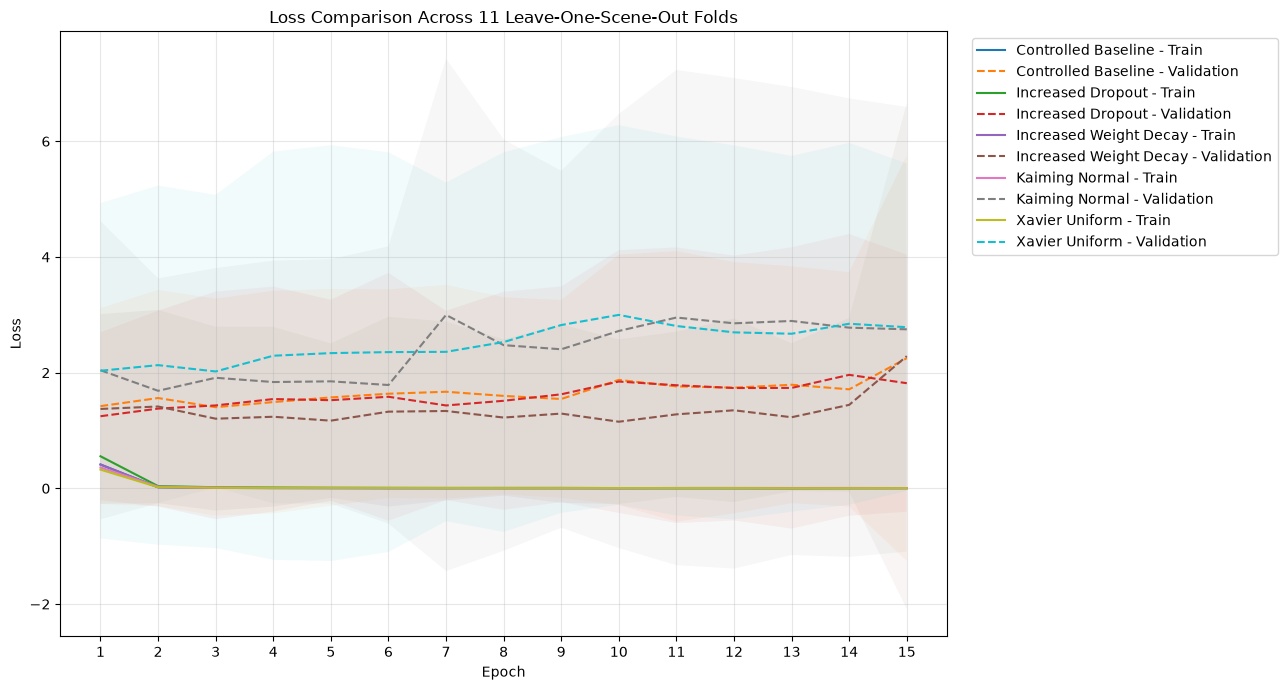

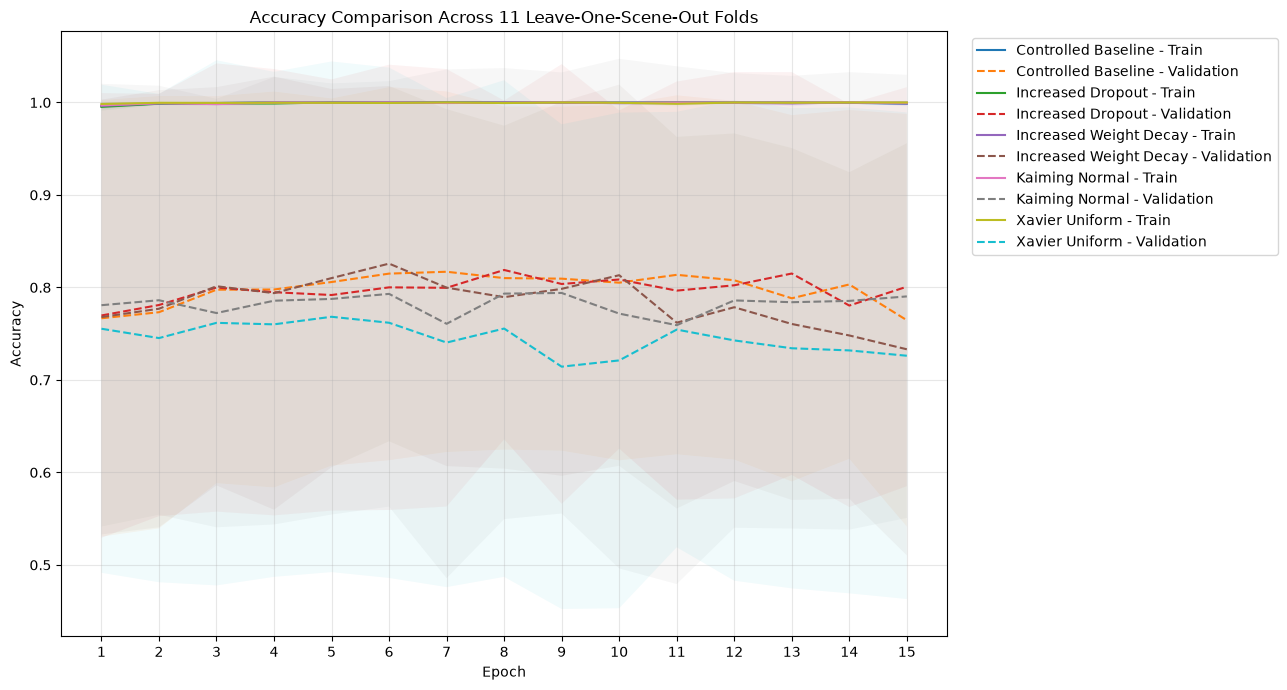


All five experiments plotted successfully.
Both comparison figures saved in the results directory.


In [32]:
# Cell 26 — Complete Training Curve Comparison

plot_histories = {
    "Controlled Baseline": controlled_baseline_fold_histories,
    "Increased Dropout": dropout_fold_histories,
    "Increased Weight Decay": weight_decay_fold_histories,
    "Kaiming Normal": kaiming_fold_histories,
    "Xavier Uniform": xavier_fold_histories,
}

# Verify that every experiment contains 11 folds
for experiment_name, histories in plot_histories.items():
    assert len(histories) == 11, (
        f"{experiment_name} has {len(histories)} folds instead of 11."
    )

metrics = [
    ("train_loss", "val_loss", "Loss"),
    ("train_accuracy", "val_accuracy", "Accuracy")
]

for train_metric, val_metric, metric_name in metrics:

    plt.figure(figsize=(13, 7))

    for experiment_name, histories in plot_histories.items():

        train_values = np.array([
            fold[train_metric] for fold in histories
        ])

        val_values = np.array([
            fold[val_metric] for fold in histories
        ])

        epochs_range = np.arange(1, train_values.shape[1] + 1)

        train_mean = train_values.mean(axis=0)
        train_std = train_values.std(axis=0)

        val_mean = val_values.mean(axis=0)
        val_std = val_values.std(axis=0)

        plt.plot(
            epochs_range,
            train_mean,
            label=f"{experiment_name} - Train"
        )

        plt.fill_between(
            epochs_range,
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.06
        )

        plt.plot(
            epochs_range,
            val_mean,
            linestyle="--",
            label=f"{experiment_name} - Validation"
        )

        plt.fill_between(
            epochs_range,
            val_mean - val_std,
            val_mean + val_std,
            alpha=0.06
        )

    plt.xlabel("Epoch")
    plt.ylabel(metric_name)
    plt.title(
        f"{metric_name} Comparison Across 11 "
        "Leave-One-Scene-Out Folds"
    )
    plt.xticks(epochs_range)
    plt.grid(alpha=0.3)
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()

    filename = f"all_experiments_{metric_name.lower()}_curves.png"

    plt.savefig(
        RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nAll five experiments plotted successfully.")
print("Both comparison figures saved in the results directory.")

In [33]:
# Cell 27 — Final Overfitting Comparison

overfitting_comparison = []

selected_epochs = [1, 2, 5, 10, 15]

for experiment_name, histories in plot_histories.items():

    for epoch in selected_epochs:
        epoch_index = epoch - 1

        train_loss = np.array([
            fold["train_loss"][epoch_index]
            for fold in histories
        ])

        val_loss = np.array([
            fold["val_loss"][epoch_index]
            for fold in histories
        ])

        train_accuracy = np.array([
            fold["train_accuracy"][epoch_index]
            for fold in histories
        ])

        val_accuracy = np.array([
            fold["val_accuracy"][epoch_index]
            for fold in histories
        ])

        overfitting_comparison.append({
            "experiment": experiment_name,
            "epoch": epoch,
            "train_loss": train_loss.mean(),
            "val_loss": val_loss.mean(),
            "loss_gap": (val_loss - train_loss).mean(),
            "train_accuracy": train_accuracy.mean(),
            "val_accuracy": val_accuracy.mean(),
            "accuracy_gap": (
                train_accuracy - val_accuracy
            ).mean()
        })

final_overfitting_df = pd.DataFrame(
    overfitting_comparison
)

display(final_overfitting_df.round(4))

final_overfitting_df.to_csv(
    RESULTS_DIR / "final_overfitting_comparison.csv",
    index=False
)

print("\nFinal overfitting comparison saved successfully.")

,experiment,epoch,train_loss,val_loss,loss_gap,train_accuracy,val_accuracy,accuracy_gap
0,Controlled Baseline,1,0.4122,1.4214,1.0092,0.9961,0.7667,0.2294
1,Controlled Baseline,2,0.0191,1.5614,1.5422,0.9989,0.7732,0.2256
2,Controlled Baseline,5,0.0035,1.5722,1.5687,0.9998,0.8059,0.1939
3,Controlled Baseline,10,0.0013,1.8754,1.8741,1.0000,0.8052,0.1948
4,Controlled Baseline,15,0.0028,2.2505,2.2477,0.9988,0.7645,0.2342
5,Increased Dropout,1,0.5548,1.2471,0.6923,0.9952,0.7697,0.2255
6,Increased Dropout,2,0.0396,1.3787,1.3391,0.9987,0.7810,0.2177
7,Increased Dropout,5,0.0101,1.5242,1.5141,1.0000,0.7918,0.2082
8,Increased Dropout,10,0.0050,1.8465,1.8415,0.9995,0.8086,0.1909
9,Increased Dropout,15,0.0056,1.8179,1.8123,0.9996,0.8008,0.1988



Final overfitting comparison saved successfully.


In [34]:
# Cell 28 — Select Final Training Epochs

weight_decay_best_epochs = []

for fold_number, fold_history in enumerate(
    weight_decay_fold_histories,
    start=1
):
    best_epoch_index = int(
        np.argmin(fold_history["val_loss"])
    )

    weight_decay_best_epochs.append({
        "fold": fold_number,
        "validation_scene": int(
            sorted(np.unique(groups_dev))[fold_number - 1]
        ),
        "best_epoch": best_epoch_index + 1,
        "best_val_loss": fold_history["val_loss"][best_epoch_index]
    })

best_epochs_df = pd.DataFrame(weight_decay_best_epochs)

display(best_epochs_df.round(4))

FINAL_EPOCHS = int(
    np.median(best_epochs_df["best_epoch"])
)

print(f"\nSelected final training epochs: {FINAL_EPOCHS}")
print("Selection method: Median best epoch across 11 validation folds.")

best_epochs_df.to_csv(
    RESULTS_DIR / "weight_decay_best_epochs.csv",
    index=False
)

print("Best epoch analysis saved successfully.")

,fold,validation_scene,best_epoch,best_val_loss
0,1,48,13,4.2599
1,2,49,14,2.2895
2,3,50,12,0.0256
3,4,51,15,0.3802
4,5,52,3,0.2952
5,6,53,1,2.3884
6,7,54,6,0.3536
7,8,55,3,0.0782
8,9,56,4,0.0005
9,10,57,2,0.2160



Selected final training epochs: 4
Selection method: Median best epoch across 11 validation folds.
Best epoch analysis saved successfully.


In [35]:
# Cell 29 — Train and Save the Final Model

import joblib
import random
import copy
import torch
import numpy as np
import pandas as pd

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")

# Fit preprocessing on development data only
final_scaler = StandardScaler()

X_dev_scaled = final_scaler.fit_transform(
    X_dev_model
).astype(np.float32)

y_dev_final = np.array([
    label_to_index[int(label)]
    for label in y_dev
], dtype=np.int64)

# Create training dataset
final_dataset = TensorDataset(
    torch.tensor(X_dev_scaled, dtype=torch.float32),
    torch.tensor(y_dev_final, dtype=torch.long)
)

final_generator = torch.Generator()
final_generator.manual_seed(SEED)

final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=final_generator
)

# Initialize selected architecture
final_model = YCBVBaselineMLP(
    input_size=INPUT_SIZE,
    num_classes=NUM_CLASSES
).to(device)

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-3
)

final_criterion = nn.CrossEntropyLoss()

# Train for the selected number of epochs
final_training_history = {
    "train_loss": [],
    "train_accuracy": []
}

for epoch in range(FINAL_EPOCHS):

    final_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in final_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        final_optimizer.zero_grad()

        outputs = final_model(inputs)
        loss = final_criterion(outputs, targets)

        loss.backward()
        final_optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    final_training_history["train_loss"].append(epoch_loss)
    final_training_history["train_accuracy"].append(epoch_accuracy)

    print(
        f"Epoch {epoch + 1}/{FINAL_EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

# Save final artifacts
model_path = MODELS_DIR / "best_model.pth"
scaler_path = MODELS_DIR / "feature_scaler.joblib"
history_path = RESULTS_DIR / "final_training_history.csv"

torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "input_size": INPUT_SIZE,
        "num_classes": NUM_CLASSES,
        "weight_decay": 1e-3,
        "learning_rate": LEARNING_RATE,
        "epochs": FINAL_EPOCHS,
        "seed": SEED,
        "label_to_index": label_to_index,
        "index_to_label": index_to_label,
        "class_id_to_name": class_id_to_name
    },
    model_path
)

joblib.dump(final_scaler, scaler_path)

pd.DataFrame(final_training_history).to_csv(
    history_path,
    index=False
)

print("\nFinal model training completed.")
print(f"Model saved: {model_path}")
print(f"Scaler saved: {scaler_path}")
print(f"Training history saved: {history_path}")
print(f"Training samples: {len(final_dataset)}")
print(f"Training epochs: {FINAL_EPOCHS}")

Epoch 1/4 | Loss: 0.4026 | Accuracy: 0.8963
Epoch 2/4 | Loss: 0.0174 | Accuracy: 0.9948
Epoch 3/4 | Loss: 0.0071 | Accuracy: 0.9987
Epoch 4/4 | Loss: 0.0045 | Accuracy: 0.9996

Final model training completed.
Model saved: /Users/mac/Documents/MLInternship_week10/models/best_model.pth
Scaler saved: /Users/mac/Documents/MLInternship_week10/models/feature_scaler.joblib
Training history saved: /Users/mac/Documents/MLInternship_week10/results/final_training_history.csv
Training samples: 2325
Training epochs: 4


FINAL TEST RESULTS — SCENE 59
Test samples: 375
Accuracy: 0.6480
Macro-F1 (all 9 classes): 0.3713
Macro-F1 (present classes): 0.6683


,precision,recall,f1-score,support
Master Chef Can,0.0000,0.0000,0.0000,0.000
Cracker Box,0.9868,1.0000,0.9934,75.000
Sugar Box,0.0000,0.0000,0.0000,0.000
Tomato Soup Can,0.8052,0.8267,0.8158,75.000
Tuna Fish Can,1.0000,0.1733,0.2955,75.000
Potted Meat Can,0.2338,0.2400,0.2368,75.000
Pitcher Base,0.0000,0.0000,0.0000,0.000
Bleach Cleanser,0.0000,0.0000,0.0000,0.000
Power Drill,1.0000,1.0000,1.0000,75.000
accuracy,0.6480,0.6480,0.6480,0.648


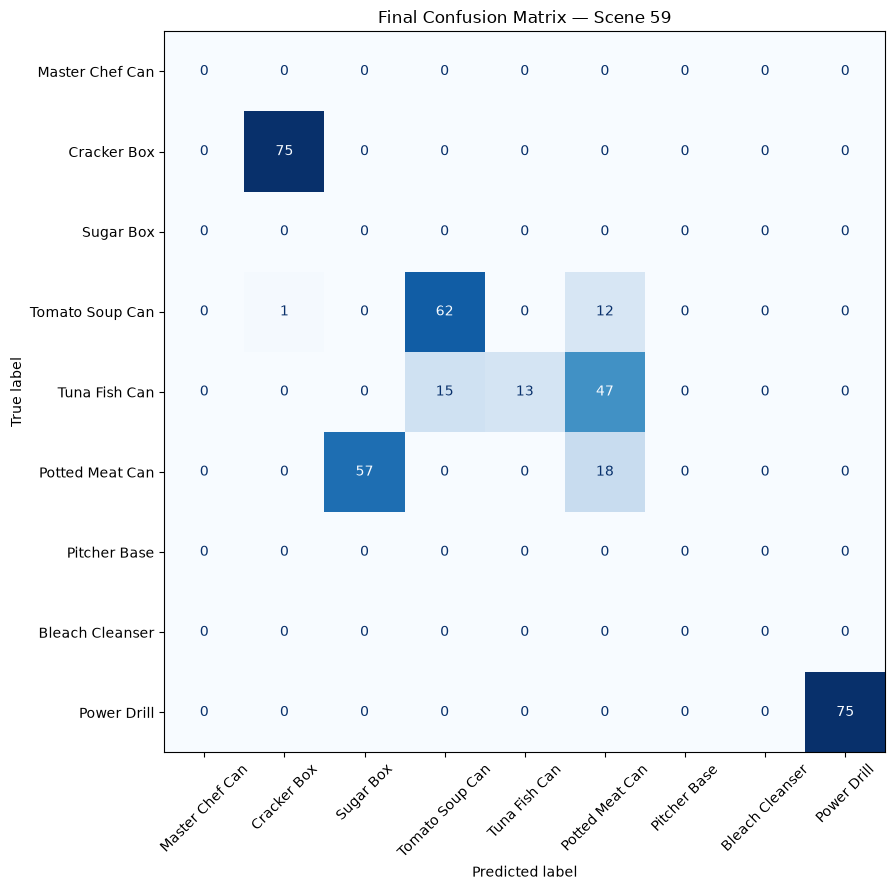


Final evaluation artifacts saved successfully.


In [36]:
# Cell 30 — Final Evaluation on Scene 59

import joblib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

device = torch.device("cpu")

# Load the finalized model and scaler
checkpoint = torch.load(
    MODELS_DIR / "best_model.pth",
    map_location=device
)

final_scaler_loaded = joblib.load(
    MODELS_DIR / "feature_scaler.joblib"
)

final_model_loaded = YCBVBaselineMLP(
    input_size=checkpoint["input_size"],
    num_classes=checkpoint["num_classes"]
).to(device)

final_model_loaded.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model_loaded.eval()

# Transform the untouched Scene 59 test data
X_test_scaled = final_scaler_loaded.transform(
    X_test_model
).astype(np.float32)

y_test_encoded = np.array([
    checkpoint["label_to_index"][int(label)]
    for label in y_test
], dtype=np.int64)

# Generate predictions
with torch.no_grad():
    test_inputs = torch.tensor(
        X_test_scaled,
        dtype=torch.float32
    ).to(device)

    test_logits = final_model_loaded(test_inputs)
    y_test_predictions = test_logits.argmax(dim=1).cpu().numpy()

# Calculate final metrics
final_accuracy = accuracy_score(
    y_test_encoded,
    y_test_predictions
)

final_macro_f1 = f1_score(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

present_classes = np.unique(y_test_encoded)

final_present_macro_f1 = f1_score(
    y_test_encoded,
    y_test_predictions,
    labels=present_classes,
    average="macro",
    zero_division=0
)

print("FINAL TEST RESULTS — SCENE 59")
print("=" * 45)
print(f"Test samples: {len(y_test_encoded)}")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Macro-F1 (all 9 classes): {final_macro_f1:.4f}")
print(f"Macro-F1 (present classes): {final_present_macro_f1:.4f}")

# Classification report
class_names = [
    checkpoint["class_id_to_name"][
        int(checkpoint["index_to_label"][i])
    ]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

# Save predictions and classification report
pd.DataFrame({
    "true_label": y_test,
    "true_class": [
        checkpoint["class_id_to_name"][int(label)]
        for label in y_test
    ],
    "predicted_label": [
        int(checkpoint["index_to_label"][int(prediction)])
        for prediction in y_test_predictions
    ],
    "predicted_class": [
        checkpoint["class_id_to_name"][
            int(checkpoint["index_to_label"][int(prediction)])
        ]
        for prediction in y_test_predictions
    ],
    "correct": y_test == np.array([
        checkpoint["index_to_label"][int(prediction)]
        for prediction in y_test_predictions
    ])
}).to_csv(
    RESULTS_DIR / "scene59_predictions.csv",
    index=False
)

report_df.to_csv(
    RESULTS_DIR / "scene59_classification_report.csv"
)

# Confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Final Confusion Matrix — Scene 59")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "scene59_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFinal evaluation artifacts saved successfully.")

In [40]:
# Cell 31 — Analyze Class Confusions

from IPython.display import display as show_table

# Raw confusion matrix
confusion_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("Confusion Matrix — Rows: True Classes | Columns: Predicted Classes")
show_table(confusion_df)

# Row-normalized confusion matrix
row_totals = cm.sum(axis=1, keepdims=True)

normalized_cm = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

normalized_confusion_df = pd.DataFrame(
    normalized_cm,
    index=class_names,
    columns=class_names
)

print("\nRow-Normalized Confusion Matrix")
show_table(normalized_confusion_df.round(3))

# Find the most frequent incorrect predictions
misclassifications = []

for true_index in range(NUM_CLASSES):
    for predicted_index in range(NUM_CLASSES):

        count = int(cm[true_index, predicted_index])

        if true_index != predicted_index and count > 0:
            misclassifications.append({
                "true_class": class_names[true_index],
                "predicted_class": class_names[predicted_index],
                "count": count
            })

misclassification_df = pd.DataFrame(misclassifications)

if not misclassification_df.empty:
    misclassification_df = misclassification_df.sort_values(
        "count",
        ascending=False
    ).reset_index(drop=True)

    print("\nMost Frequent Misclassifications")
    show_table(misclassification_df.head(15))

    misclassification_df.to_csv(
        RESULTS_DIR / "scene59_misclassifications.csv",
        index=False
    )
else:
    print("No misclassifications found.")

print("\nConfusion analysis saved successfully.")

Confusion Matrix — Rows: True Classes | Columns: Predicted Classes


,Master Chef Can,Cracker Box,Sugar Box,Tomato Soup Can,Tuna Fish Can,Potted Meat Can,Pitcher Base,Bleach Cleanser,Power Drill
Master Chef Can,0,0,0,0,0,0,0,0,0
Cracker Box,0,75,0,0,0,0,0,0,0
Sugar Box,0,0,0,0,0,0,0,0,0
Tomato Soup Can,0,1,0,62,0,12,0,0,0
Tuna Fish Can,0,0,0,15,13,47,0,0,0
Potted Meat Can,0,0,57,0,0,18,0,0,0
Pitcher Base,0,0,0,0,0,0,0,0,0
Bleach Cleanser,0,0,0,0,0,0,0,0,0
Power Drill,0,0,0,0,0,0,0,0,75



Row-Normalized Confusion Matrix


,Master Chef Can,Cracker Box,Sugar Box,Tomato Soup Can,Tuna Fish Can,Potted Meat Can,Pitcher Base,Bleach Cleanser,Power Drill
Master Chef Can,0.0,0.000,0.00,0.000,0.000,0.000,0.0,0.0,0.0
Cracker Box,0.0,1.000,0.00,0.000,0.000,0.000,0.0,0.0,0.0
Sugar Box,0.0,0.000,0.00,0.000,0.000,0.000,0.0,0.0,0.0
Tomato Soup Can,0.0,0.013,0.00,0.827,0.000,0.160,0.0,0.0,0.0
Tuna Fish Can,0.0,0.000,0.00,0.200,0.173,0.627,0.0,0.0,0.0
Potted Meat Can,0.0,0.000,0.76,0.000,0.000,0.240,0.0,0.0,0.0
Pitcher Base,0.0,0.000,0.00,0.000,0.000,0.000,0.0,0.0,0.0
Bleach Cleanser,0.0,0.000,0.00,0.000,0.000,0.000,0.0,0.0,0.0
Power Drill,0.0,0.000,0.00,0.000,0.000,0.000,0.0,0.0,1.0



Most Frequent Misclassifications


,true_class,predicted_class,count
0,Potted Meat Can,Sugar Box,57
1,Tuna Fish Can,Potted Meat Can,47
2,Tuna Fish Can,Tomato Soup Can,15
3,Tomato Soup Can,Potted Meat Can,12
4,Tomato Soup Can,Cracker Box,1



Confusion analysis saved successfully.
